# NYC Yellow Taxi Operations Analysis

**Project type:** Exploratory Data Analysis (EDA)  
**Dataset:** NYC Yellow Taxi trip records, 2023  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, GeoPandas

This project analyzes 2023 NYC Yellow Taxi trip records to explore demand patterns, trip economics, geographic activity, and operational opportunities.


## Business Objective

Analyze taxi trip activity across time, geography, trip characteristics, and fare components to identify patterns that can inform fleet positioning, operational planning, and service improvements.


## Business Questions

- When is taxi demand highest, and how does it vary across weekdays and weekends?
- How do trip distance and duration relate to fare amounts?
- Which pickup zones generate the most activity?
- What operational recommendations can be drawn from the observed patterns?


## Dataset Overview

The analysis uses the 12 monthly NYC Yellow Taxi trip-record files for 2023. The records include pickup and drop-off timestamps, pickup and drop-off zone IDs, trip distance, passenger count, fare and tip amounts, payment type, and additional charges.

The monthly files are stored in Parquet format. Taxi-zone lookup data is used to associate location IDs with geographic zones and support spatial analysis.

**Source:** [NYC Taxi & Limousine Commission trip-record data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) · [Yellow Taxi data dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)


### Geographic Reference Data

Taxi-zone IDs identify the pickup and drop-off zones in each trip record. The zone lookup and shapefile provide zone names, boroughs, and geographic boundaries for aggregating and mapping trip activity.


## 1. Data Loading and Sampling


### Libraries and Configuration


In [1]:
# Import warnings
import warnings
warnings.filterwarnings('ignore') 


In [2]:
# Import the libraries you will be using for analysis



import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 1.26.4
pandas version: 2.2.2
matplotlib version: 3.5.2
seaborn version: 0.13.2


### Load Monthly Trip Records


The 2023 Yellow Taxi records are supplied as one Parquet file per month. This workflow processes only the 12 original monthly files, samples within pickup-date and pickup-hour groups, and writes one reusable analysis dataset. Previously generated sample files are explicitly excluded.


### Sampling Strategy


In [10]:
from pathlib import Path
import pandas as pd

# Folder containing the NYC Taxi monthly Parquet files
data_dir = Path(
    r"C:\Users\Gill\Downloads\Datasets and Dictionary-NYC (1)\Datasets and Dictionary\trip_records"
)

# Find the monthly files
monthly_files = sorted(
    data_dir.glob("2023-*.parquet"),
    key=lambda file: int(file.stem.split("-")[1])
)

# Validate the files
if not data_dir.exists():
    raise FileNotFoundError(f"Folder not found: {data_dir}")

if len(monthly_files) != 12:
    raise FileNotFoundError(
        f"Expected 12 monthly Parquet files, but found {len(monthly_files)}.\n"
        f"Folder checked: {data_dir}\n"
        f"Files found: {[file.name for file in monthly_files]}"
    )

print(f"Found {len(monthly_files)} monthly files:")
for file in monthly_files:
    print(file.name)
    
    
# Sample 0.7% of trips from each pickup date-hour group
sampled_months = []

for file in monthly_files:
    print(f"Processing {file.name}...")

    # Load one month's data
    month_df = pd.read_parquet(file)

    # Identify pickup date and hour
    month_df["tpep_pickup_datetime"] = pd.to_datetime(
        month_df["tpep_pickup_datetime"], errors="coerce"
    )

    month_df = month_df.dropna(subset=["tpep_pickup_datetime"])

    month_df["pickup_date"] = month_df["tpep_pickup_datetime"].dt.date
    month_df["pickup_hour"] = month_df["tpep_pickup_datetime"].dt.hour

    # Randomly sample 0.7% within each date-hour group
    month_sample = (
        month_df.groupby(["pickup_date", "pickup_hour"], group_keys=False)
        .sample(frac=0.007, random_state=42)
    )

    sampled_months.append(month_sample)

    print(f"  Sampled {len(month_sample):,} records")

# Combine all monthly samples
sampled_df = pd.concat(sampled_months, ignore_index=True)

# Save the sample in the same folder as the original files
sample_path = data_dir / "sampled_nyc_taxi_data.parquet"
sampled_df.to_parquet(sample_path, index=False)

print("\nSampling complete!")
print(f"Total sampled records: {len(sampled_df):,}")
print(f"Saved to: {sample_path}")

Found 12 monthly files:
2023-1.parquet
2023-2.parquet
2023-3.parquet
2023-4.parquet
2023-5.parquet
2023-6.parquet
2023-7.parquet
2023-8.parquet
2023-9.parquet
2023-10.parquet
2023-11.parquet
2023-12.parquet
Processing 2023-1.parquet...
  Sampled 21,288 records
Processing 2023-2.parquet...
  Sampled 23,617 records
Processing 2023-3.parquet...
  Sampled 22,939 records
Processing 2023-4.parquet...
  Sampled 19,546 records
Processing 2023-5.parquet...
  Sampled 20,208 records
Processing 2023-6.parquet...
  Sampled 22,810 records
Processing 2023-7.parquet...
  Sampled 24,363 records
Processing 2023-8.parquet...
  Sampled 20,117 records
Processing 2023-9.parquet...
  Sampled 19,724 records
Processing 2023-10.parquet...
  Sampled 24,408 records
Processing 2023-11.parquet...
  Sampled 23,115 records
Processing 2023-12.parquet...
  Sampled 23,352 records

Sampling complete!
Total sampled records: 265,487
Saved to: C:\Users\Gill\Downloads\Datasets and Dictionary-NYC (1)\Datasets and Dictionary\t

## 2. Data Cleaning and Quality Checks


Load the generated analysis dataset. Run the data-loading and sampling section first if the file does not yet exist.


In [11]:
sample_path = data_dir / "sampled_nyc_taxi_data.parquet"

if not sample_path.exists():
    raise FileNotFoundError(
        "Sample file not found. Run the Sampling Strategy section first."
    )

df = pd.read_parquet(sample_path)

print(f"Loaded {len(df):,} sampled trip records.")

Loaded 265,487 sampled trip records.


In [12]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour,Airport_fee
0,1,2023-01-01 00:59:47,2023-01-01 01:23:42,NaN,0.00,NaN,None,68,45,0,...,0.5,0.00,0.0,1.0,39.30,NaN,NaN,2023-01-01,0,NaN
1,2,2023-01-01 00:18:34,2023-01-01 00:23:55,1.0,0.99,1.0,N,144,211,2,...,0.5,0.00,0.0,1.0,12.20,2.5,0.0,2023-01-01,0,NaN
2,2,2023-01-01 00:32:27,2023-01-01 00:37:01,2.0,0.92,1.0,N,79,107,1,...,0.5,3.05,0.0,1.0,15.25,2.5,0.0,2023-01-01,0,NaN
3,1,2023-01-01 00:26:11,2023-01-01 00:40:21,2.0,2.30,1.0,Y,48,238,1,...,0.5,4.60,0.0,1.0,23.10,2.5,0.0,2023-01-01,0,NaN
4,2,2023-01-01 00:10:09,2023-01-01 00:29:28,1.0,2.27,1.0,N,68,137,1,...,0.5,4.68,0.0,1.0,28.08,2.5,0.0,2023-01-01,0,NaN


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265487 entries, 0 to 265486
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               265487 non-null  int64         
 1   tpep_pickup_datetime   265487 non-null  datetime64[us]
 2   tpep_dropoff_datetime  265487 non-null  datetime64[us]
 3   passenger_count        256379 non-null  float64       
 4   trip_distance          265487 non-null  float64       
 5   RatecodeID             256379 non-null  float64       
 6   store_and_fwd_flag     256379 non-null  object        
 7   PULocationID           265487 non-null  int64         
 8   DOLocationID           265487 non-null  int64         
 9   payment_type           265487 non-null  int64         
 10  fare_amount            265487 non-null  float64       
 11  extra                  265487 non-null  float64       
 12  mta_tax                265487 non-null  floa

### Column Standardization


#### Remove Unnecessary Index Columns


In [20]:
# Fix the index and drop any columns that are not needed
df.reset_index(drop=True, inplace=True)
df.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour
0,1,2023-01-01 00:59:47,2023-01-01 01:23:42,NaN,0.00,NaN,None,68,45,0,...,0.0,0.5,0.00,0.0,1.0,39.30,NaN,NaN,2023-01-01,0
1,2,2023-01-01 00:18:34,2023-01-01 00:23:55,1.0,0.99,1.0,N,144,211,2,...,1.0,0.5,0.00,0.0,1.0,12.20,2.5,0.0,2023-01-01,0
2,2,2023-01-01 00:32:27,2023-01-01 00:37:01,2.0,0.92,1.0,N,79,107,1,...,1.0,0.5,3.05,0.0,1.0,15.25,2.5,0.0,2023-01-01,0
3,1,2023-01-01 00:26:11,2023-01-01 00:40:21,2.0,2.30,1.0,Y,48,238,1,...,3.5,0.5,4.60,0.0,1.0,23.10,2.5,0.0,2023-01-01,0
4,2,2023-01-01 00:10:09,2023-01-01 00:29:28,1.0,2.27,1.0,N,68,137,1,...,1.0,0.5,4.68,0.0,1.0,28.08,2.5,0.0,2023-01-01,0


In [14]:
# Investigate columns that differ only by capitalization
fee_columns = ["airport_fee", "Airport_fee"]

print("Non-null counts:")
print(df[fee_columns].notna().sum())

print("\nMissing-value counts:")
print(df[fee_columns].isna().sum())

print("\nDescriptive statistics:")
print(df[fee_columns].describe())

print("\nSample values:")
display(df[fee_columns].head(15))

Non-null counts:
airport_fee     20762
Airport_fee    235617
dtype: int64

Missing-value counts:
airport_fee    244725
Airport_fee     29870
dtype: int64

Descriptive statistics:
        airport_fee    Airport_fee
count  20762.000000  235617.000000
mean       0.111622       0.146340
std        0.356475       0.474118
min        0.000000      -1.750000
25%        0.000000       0.000000
50%        0.000000       0.000000
75%        0.000000       0.000000
max        1.250000       1.750000

Sample values:


,airport_fee,Airport_fee
0,NaN,NaN
1,0.0,NaN
2,0.0,NaN
3,0.0,NaN
4,0.0,NaN
5,0.0,NaN
6,0.0,NaN
7,NaN,NaN
8,0.0,NaN
9,0.0,NaN


In [15]:
# Check whether both columns contain values in the same rows
both_present = df["airport_fee"].notna() & df["Airport_fee"].notna()

print("Rows where both columns have values:", both_present.sum())

print("\nRows where only airport_fee has a value:",
      (df["airport_fee"].notna() & df["Airport_fee"].isna()).sum())

print("\nRows where only Airport_fee has a value:",
      (df["airport_fee"].isna() & df["Airport_fee"].notna()).sum())

print("\nRows where both columns have values:")
display(df.loc[both_present, ["airport_fee", "Airport_fee"]].head(20))

Rows where both columns have values: 0

Rows where only airport_fee has a value: 20762

Rows where only Airport_fee has a value: 235617

Rows where both columns have values:


,airport_fee,Airport_fee


#### Standardizing Duplicate Airport Fee Columns

**Problem identified**

During the initial data inspection, two columns representing airport fees were identified: `airport_fee` and `Airport_fee`. Although their names differ only in capitalization, they have different patterns of missing values.

**Investigation**

The two columns were examined to determine whether they contained overlapping values.

- `airport_fee` contained 20,762 non-null values.
- `Airport_fee` contained 235,617 non-null values.
- No records contained non-null values in both columns.

These findings indicated that the columns contained complementary non-null values rather than overlapping values in the sampled dataset.

**Cleaning decision**

The non-null values from both columns were consolidated into a single standardized column, `airport_fee`, using pandas' `combine_first()` method. The redundant `Airport_fee` column was then removed.

This approach preserves the available values from both columns without overwriting one with the other.

**Validation**

After consolidation, the resulting column's missing-value count and descriptive statistics were checked to verify the transformation.

**Limitation**

Although the columns contained complementary values, their differing missing-value patterns do not establish why the values were stored separately. The consolidation standardizes the dataset but does not independently verify the underlying source of each airport-fee value.

In [ ]:
# Combine the two airport fee columns
df['airport_fee_combined'] = df['airport_fee'].combine_first(df['Airport_fee'])



In [ ]:
df.drop(columns=['airport_fee', 'Airport_fee'], inplace=True)
df.rename(columns={'airport_fee_combined': 'airport_fee'}, inplace=True)



In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 265487 entries, 0 to 265486
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               265487 non-null  int64         
 1   tpep_pickup_datetime   265487 non-null  datetime64[us]
 2   tpep_dropoff_datetime  265487 non-null  datetime64[us]
 3   passenger_count        256379 non-null  float64       
 4   trip_distance          265487 non-null  float64       
 5   RatecodeID             256379 non-null  float64       
 6   store_and_fwd_flag     256379 non-null  object        
 7   PULocationID           265487 non-null  int64         
 8   DOLocationID           265487 non-null  int64         
 9   payment_type           265487 non-null  int64         
 10  fare_amount            265487 non-null  float64       
 11  extra                  265487 non-null  float64       
 12  mta_tax                265487 non-null  floa

#### Review Invalid Monetary Values


In [22]:
# check where values of fare amount are negative

(df['fare_amount'] < 0).sum()


0

In [23]:
monetary_columns = ['fare_amount', 'extra', 'mta_tax', 'tip_amount', 
                    'tolls_amount', 'improvement_surcharge', 'total_amount',
                    'congestion_surcharge', 'airport_fee']

for col in monetary_columns:
    count = (df[col] < 0).sum()
    if count > 0:
        print(f"{col}: {count} negative values")


mta_tax: 14 negative values
improvement_surcharge: 15 negative values
total_amount: 15 negative values
congestion_surcharge: 9 negative values
airport_fee: 4 negative values


In [24]:
# Filter rows with any negative monetary values
mask = (
    (df['extra'] < 0) |
    (df['mta_tax'] < 0) |
    (df['improvement_surcharge'] < 0) |
    (df['total_amount'] < 0) |
    (df['congestion_surcharge'] < 0) |
    (df['airport_fee'] < 0)
)

df_neg = df[mask]

# Display their RatecodeID values
print(df_neg['RatecodeID'].value_counts(dropna=False))



RatecodeID
1.0    9
2.0    5
3.0    1
Name: count, dtype: int64


In [25]:
df_neg[['RatecodeID', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 
        'tolls_amount', 'improvement_surcharge', 'total_amount',
        'congestion_surcharge', 'airport_fee']]



,RatecodeID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
6265,1.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
42089,2.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
59829,1.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-1.50,0.0,0.00
65111,1.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-3.25,0.0,-1.75
83653,2.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00
89970,1.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-5.25,-2.5,-1.25
97827,1.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-2.75,0.0,-1.25
124829,3.0,0.0,0.0,0.0,0.0,0.0,-1.0,-2.75,0.0,-1.75
145585,1.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-1.50,0.0,0.00
190820,2.0,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00


In [26]:
# Inspect all records containing negative monetary values
display(df.loc[mask, monetary_columns + [
    "VendorID",
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "payment_type",
    "PULocationID",
    "DOLocationID"
]])

,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,PULocationID,DOLocationID
6265,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00,2,2023-01-11 00:00:21,2023-01-11 00:00:34,1.0,0.00,2,263,263
42089,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00,2,2023-03-28 14:38:01,2023-03-28 14:38:13,1.0,0.00,2,107,107
59829,0.0,0.0,-0.5,0.0,0.0,-1.0,-1.50,0.0,0.00,2,2023-06-20 10:02:26,2023-06-20 10:02:43,1.0,0.04,2,70,70
65111,0.0,0.0,-0.5,0.0,0.0,-1.0,-3.25,0.0,-1.75,2,2023-06-27 10:10:01,2023-06-27 10:10:14,2.0,0.00,2,132,132
83653,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00,2,2023-08-25 21:14:13,2023-08-25 21:19:14,1.0,0.54,2,238,238
89970,0.0,0.0,-0.5,0.0,0.0,-1.0,-5.25,-2.5,-1.25,2,2023-02-04 13:23:51,2023-02-04 13:46:55,1.0,0.00,2,138,234
97827,0.0,0.0,-0.5,0.0,0.0,-1.0,-2.75,0.0,-1.25,2,2023-02-15 13:55:06,2023-02-15 13:56:23,1.0,0.01,2,138,138
124829,0.0,0.0,0.0,0.0,0.0,-1.0,-2.75,0.0,-1.75,2,2023-04-23 19:29:45,2023-04-23 19:29:54,2.0,0.00,2,132,132
145585,0.0,0.0,-0.5,0.0,0.0,-1.0,-1.50,0.0,0.00,2,2023-05-19 15:15:04,2023-05-19 15:15:41,1.0,0.00,2,226,226
190820,0.0,0.0,-0.5,0.0,0.0,-1.0,-4.00,-2.5,0.00,2,2023-09-26 11:40:03,2023-09-26 11:40:28,2.0,0.03,2,163,163


In [27]:
# Assess the impact of removing rows with negative monetary values

negative_mask = (df[monetary_columns] < 0).any(axis=1)

print("Total records before filtering:", len(df))
print("Records containing negative monetary values:", negative_mask.sum())
print("Records without negative monetary values:", (~negative_mask).sum())
print(
    "Percentage of records flagged:",
    round(negative_mask.mean() * 100, 4),
    "%"
)

Total records before filtering: 265487
Records containing negative monetary values: 15
Records without negative monetary values: 265472
Percentage of records flagged: 0.0056 %


In [31]:
# Count records that fail each individual condition

print("Total records:", len(df))

print("Fare amount <= 0:", (df["fare_amount"] <= 0).sum())
print("Tip amount <= 0:", (df["tip_amount"] <= 0).sum())
print("Trip distance <= 0:", (df["trip_distance"] <= 0).sum())

print("\nMissing values in these columns:")
print(df[["fare_amount", "tip_amount", "trip_distance"]].isna().sum())

Total records: 265487
Fare amount <= 0: 97
Tip amount <= 0: 60648
Trip distance <= 0: 5135

Missing values in these columns:
fare_amount      0
tip_amount       0
trip_distance    0
dtype: int64


In [30]:
# Remove records with non-positive fare amounts or trip distances
df_cleaned = df[
    (df["fare_amount"] > 0) &
    (df["trip_distance"] > 0)
].reset_index(drop=True)

print("Original records:", len(df))
print("Records after filtering:", len(df_cleaned))
print("Records removed:", len(df) - len(df_cleaned))

Original records: 265487
Records after filtering: 260308
Records removed: 5179


In [32]:
# Verify the cleaned dataset

print("Non-positive fare amounts:",
      (df_cleaned["fare_amount"] <= 0).sum())

print("Non-positive trip distances:",
      (df_cleaned["trip_distance"] <= 0).sum())

print("Zero-tip trips retained:",
      (df_cleaned["tip_amount"] == 0).sum())

print("Shape of cleaned dataset:", df_cleaned.shape)

Non-positive fare amounts: 0
Non-positive trip distances: 0
Zero-tip trips retained: 56783
Shape of cleaned dataset: (260308, 21)


Filtering non-positive fares and trip distances

Records with non-positive fare amounts or trip distances were excluded from the analytical dataset. Zero-tip trips were retained because the absence of a tip does not necessarily indicate an invalid trip. This approach removed 5,179 records, leaving 260,308 records for further analysis. The decision to retain zero-tip trips differs from the original assignment's filtering rule and is documented as a methodological adjustment.

### Missing-Value Assessment and Treatment


#### Missing-Value Profile


In [33]:
# Find the proportion of missing values in each column
df_cleaned.isna().mean().sort_values(ascending=False)

passenger_count          0.027406
airport_fee              0.027406
RatecodeID               0.027406
store_and_fwd_flag       0.027406
congestion_surcharge     0.027406
VendorID                 0.000000
mta_tax                  0.000000
pickup_date              0.000000
total_amount             0.000000
improvement_surcharge    0.000000
tolls_amount             0.000000
tip_amount               0.000000
fare_amount              0.000000
extra                    0.000000
tpep_pickup_datetime     0.000000
payment_type             0.000000
DOLocationID             0.000000
PULocationID             0.000000
trip_distance            0.000000
tpep_dropoff_datetime    0.000000
pickup_hour              0.000000
dtype: float64

In [34]:
# Review the structure and non-null counts
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260308 entries, 0 to 260307
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               260308 non-null  int64         
 1   tpep_pickup_datetime   260308 non-null  datetime64[us]
 2   tpep_dropoff_datetime  260308 non-null  datetime64[us]
 3   passenger_count        253174 non-null  float64       
 4   trip_distance          260308 non-null  float64       
 5   RatecodeID             253174 non-null  float64       
 6   store_and_fwd_flag     253174 non-null  object        
 7   PULocationID           260308 non-null  int64         
 8   DOLocationID           260308 non-null  int64         
 9   payment_type           260308 non-null  int64         
 10  fare_amount            260308 non-null  float64       
 11  extra                  260308 non-null  float64       
 12  mta_tax                260308 non-null  floa

#### Passenger Counts


In [35]:
# Display the rows with null values
# Impute NaN values in 'passenger_count'
df_cleaned[df_cleaned['passenger_count'].isna()]


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour
15,2,2023-01-01 00:39:50,2023-01-01 00:54:29,NaN,7.53,NaN,None,213,7,0,...,0.0,0.5,4.00,6.55,1.0,43.02,NaN,NaN,2023-01-01,0
69,2,2023-01-01 01:15:34,2023-01-01 01:29:55,NaN,3.01,NaN,None,209,234,0,...,0.0,0.5,2.86,0.00,1.0,31.45,NaN,NaN,2023-01-01,1
75,2,2023-01-01 02:58:37,2023-01-01 03:25:36,NaN,10.74,NaN,None,97,238,0,...,0.0,0.5,9.59,0.00,1.0,57.53,NaN,NaN,2023-01-01,2
76,2,2023-01-01 02:39:20,2023-01-01 02:55:31,NaN,6.40,NaN,None,107,97,0,...,0.0,0.5,6.48,0.00,1.0,38.89,NaN,NaN,2023-01-01,2
80,2,2023-01-01 02:46:41,2023-01-01 02:53:52,NaN,1.36,NaN,None,229,137,0,...,0.0,0.5,1.70,0.00,1.0,18.66,NaN,NaN,2023-01-01,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260291,2,2023-12-31 23:20:13,2023-12-31 23:37:42,NaN,8.31,NaN,None,116,246,0,...,0.0,0.5,0.00,0.00,1.0,35.57,NaN,NaN,2023-12-31,23
260297,2,2023-12-31 23:46:00,2023-12-31 23:50:00,NaN,0.81,NaN,None,170,234,0,...,0.0,0.5,3.15,0.00,1.0,18.89,NaN,NaN,2023-12-31,23
260298,2,2023-12-31 23:01:04,2023-12-31 23:23:37,NaN,6.58,NaN,None,238,211,0,...,0.0,0.5,0.00,0.00,1.0,33.90,NaN,NaN,2023-12-31,23
260301,2,2023-12-31 23:28:44,2023-12-31 23:51:48,NaN,6.61,NaN,None,238,114,0,...,0.0,0.5,0.00,0.00,1.0,34.78,NaN,NaN,2023-12-31,23


In [36]:
#The missing-value assessment identified records with null passenger_count values. These records also appear to have missing values in other columns, including RatecodeID, store_and_fwd_flag, congestion_surcharge, and airport_fee. The missing passenger counts were not resolved by the earlier filtering of non-positive fares and trip distances. Their treatment will be determined after examining the passenger-count distribution and the extent of missingness.

In [37]:
# Examine passenger-count frequencies, including missing values
df_cleaned["passenger_count"].value_counts(dropna=False).sort_index()

passenger_count
0.0      3906
1.0    190558
2.0     38313
3.0      9586
4.0      5346
5.0      3260
6.0      2205
NaN      7134
Name: count, dtype: int64

In [38]:
df_cleaned['passenger_count'].describe()


count    253174.000000
mean          1.370030
std           0.891682
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           6.000000
Name: passenger_count, dtype: float64

In [39]:
# Check whether missing values occur in the same records
missing_columns = [
    "passenger_count",
    "RatecodeID",
    "store_and_fwd_flag",
    "congestion_surcharge",
    "airport_fee"
]

missing_pattern = df_cleaned[missing_columns].isna()

print("Missing-value counts:")
print(missing_pattern.sum())

print("\nRecords with missing values in all five columns:",
      missing_pattern.all(axis=1).sum())

print("\nRecords with at least one missing value in these columns:",
      missing_pattern.any(axis=1).sum())

Missing-value counts:
passenger_count         7134
RatecodeID              7134
store_and_fwd_flag      7134
congestion_surcharge    7134
airport_fee             7134
dtype: int64

Records with missing values in all five columns: 7134

Records with at least one missing value in these columns: 7134


Finding: Missing-value pattern

A missing-value assessment identified 7,134 records with missing values in passenger_count, RatecodeID, store_and_fwd_flag, congestion_surcharge, and airport_fee. These missing values occur together in the same records. The pattern has been documented, but the underlying reason for the missingness has not been established. No imputation has been applied at this stage.

In [40]:
# Inspect records with zero passenger counts
display(
    df_cleaned.loc[
        df_cleaned["passenger_count"] == 0
    ].head(10)
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour
127,1,2023-01-01 03:22:22,2023-01-01 03:28:51,0.0,1.1,1.0,N,113,79,1,...,3.50,0.5,1.50,0.0,1.0,15.10,2.5,0.00,2023-01-01,3
158,1,2023-01-01 06:38:21,2023-01-01 07:34:58,0.0,45.4,5.0,N,233,265,2,...,0.00,0.0,0.00,0.0,1.0,151.00,0.0,0.00,2023-01-01,6
173,1,2023-01-01 08:29:27,2023-01-01 08:34:10,0.0,0.8,1.0,N,142,142,1,...,2.50,0.5,2.10,0.0,1.0,12.60,2.5,0.00,2023-01-01,8
206,1,2023-01-01 10:06:39,2023-01-01 10:24:31,0.0,4.2,1.0,N,143,224,2,...,2.50,0.5,0.00,0.0,1.0,24.50,2.5,0.00,2023-01-01,10
278,1,2023-01-01 13:50:51,2023-01-01 13:57:52,0.0,1.8,1.0,N,234,125,2,...,2.50,0.5,0.00,0.0,1.0,14.00,2.5,0.00,2023-01-01,13
284,1,2023-01-01 13:05:33,2023-01-01 13:14:58,0.0,0.8,1.0,N,163,162,2,...,2.50,0.5,0.00,0.0,1.0,12.60,2.5,0.00,2023-01-01,13
297,1,2023-01-01 14:28:37,2023-01-01 14:39:09,0.0,1.5,1.0,N,107,158,1,...,2.50,0.5,3.05,0.0,1.0,18.45,2.5,0.00,2023-01-01,14
321,1,2023-01-01 15:22:00,2023-01-01 15:55:07,0.0,12.0,1.0,Y,138,181,1,...,6.25,0.5,11.10,0.0,1.0,66.65,0.0,1.25,2023-01-01,15
355,1,2023-01-01 16:04:14,2023-01-01 16:22:57,0.0,3.3,1.0,N,144,246,2,...,2.50,0.5,0.00,0.0,1.0,24.50,2.5,0.00,2023-01-01,16
418,1,2023-01-01 18:51:01,2023-01-01 18:59:56,0.0,1.4,1.0,N,234,224,1,...,2.50,0.5,1.00,0.0,1.0,15.00,2.5,0.00,2023-01-01,18


Passenger-count assessment

The passenger-count column contains 7,134 missing values and 3,906 records with a value of zero. Inspection of sample zero-count records shows that these records can have positive fares, positive trip distances, and valid timestamps. The available evidence does not establish whether zero values represent genuine observations or recording errors. Therefore, zero values are retained rather than automatically replaced with one, and the limitation is documented.

#### Rate Code


In [41]:
# Examine rate-code frequencies, including missing values
df_cleaned["RatecodeID"].value_counts(dropna=False)

RatecodeID
1.0     239989
2.0       9913
NaN       7134
99.0      1295
3.0        782
5.0        673
4.0        522
Name: count, dtype: int64

In [42]:
# Inspect records with RatecodeID = 99
display(
    df_cleaned.loc[
        df_cleaned["RatecodeID"] == 99
    ].head(10)
)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_date,pickup_hour
331,1,2023-01-01 15:39:19,2023-01-01 15:56:58,1.0,2.1,99.0,N,225,17,1,...,0.0,0.5,0.0,0.0,1.0,20.0,0.0,0.0,2023-01-01,15
569,1,2023-01-02 09:23:09,2023-01-02 09:38:34,1.0,0.8,99.0,N,179,7,1,...,0.0,0.5,0.0,0.0,1.0,16.7,0.0,0.0,2023-01-02,9
585,1,2023-01-02 10:21:28,2023-01-02 10:37:04,1.0,1.1,99.0,N,198,102,1,...,0.0,0.5,0.0,0.0,1.0,18.0,0.0,0.0,2023-01-02,10
992,1,2023-01-03 06:59:22,2023-01-03 08:09:56,1.0,1.7,99.0,N,168,153,1,...,0.0,0.5,0.0,0.0,1.0,29.0,0.0,0.0,2023-01-03,6
1057,1,2023-01-03 09:43:35,2023-01-03 10:05:42,1.0,1.6,99.0,N,182,242,1,...,0.0,0.5,0.0,0.0,1.0,20.0,0.0,0.0,2023-01-03,9
1115,1,2023-01-03 10:32:38,2023-01-03 10:51:40,1.0,1.6,99.0,N,229,170,1,...,0.0,0.5,0.0,0.0,1.0,19.0,0.0,0.0,2023-01-03,10
1673,1,2023-01-04 09:00:40,2023-01-04 09:34:20,1.0,4.0,99.0,N,177,33,1,...,0.0,0.5,0.0,0.0,1.0,24.0,0.0,0.0,2023-01-04,9
1719,1,2023-01-04 11:18:57,2023-01-04 11:32:04,1.0,2.0,99.0,N,247,168,1,...,0.0,0.5,0.0,0.0,1.0,20.0,0.0,0.0,2023-01-04,11
2240,1,2023-01-05 06:03:04,2023-01-05 06:16:36,1.0,1.3,99.0,N,95,197,1,...,0.0,0.5,0.0,0.0,1.0,19.0,0.0,0.0,2023-01-05,6
2395,1,2023-01-05 11:24:43,2023-01-05 11:48:20,1.0,2.5,99.0,N,256,97,1,...,0.0,0.5,0.0,0.0,1.0,21.0,0.0,0.0,2023-01-05,11


In [43]:
# Investigate records with RatecodeID = 99

rate_99 = df_cleaned[df_cleaned["RatecodeID"] == 99]

print("Total records with RatecodeID 99:", len(rate_99))

print("\nRecords by VendorID:")
print(rate_99["VendorID"].value_counts(dropna=False))

print("\nRecords by payment_type:")
print(rate_99["payment_type"].value_counts(dropna=False))

print("\nRecords by month:")
print(
    rate_99["tpep_pickup_datetime"]
    .dt.month
    .value_counts()
    .sort_index()
)

Total records with RatecodeID 99: 1295

Records by VendorID:
VendorID
1    1295
Name: count, dtype: int64

Records by payment_type:
payment_type
1    1295
Name: count, dtype: int64

Records by month:
tpep_pickup_datetime
1      83
2      76
3      99
4     107
5     103
6      87
7      87
8     125
9      98
10    139
11    148
12    143
Name: count, dtype: int64


The official NYC TLC data dictionary defines RatecodeID = 99 as Null/unknown. The 1,295 records containing this code have therefore been retained as a documented unknown category rather than treated as invalid rate codes. A further 7,134 records have missing RatecodeID values. These missing values occur alongside missing values in passenger_count, store_and_fwd_flag, congestion_surcharge, and airport_fee. Their treatment will be considered separately rather than assigning arbitrary replacement values.

#### Congestion Surcharge


In [44]:
# Examine congestion-surcharge values, including missing values
df_cleaned["congestion_surcharge"].value_counts(dropna=False)

congestion_surcharge
2.5    235303
0.0     17871
NaN      7134
Name: count, dtype: int64

In [45]:
# Check missing values in the current cleaned dataset
df_cleaned.isna().sum()

VendorID                    0
tpep_pickup_datetime        0
tpep_dropoff_datetime       0
passenger_count          7134
trip_distance               0
RatecodeID               7134
store_and_fwd_flag       7134
PULocationID                0
DOLocationID                0
payment_type                0
fare_amount                 0
extra                       0
mta_tax                     0
tip_amount                  0
tolls_amount                0
improvement_surcharge       0
total_amount                0
congestion_surcharge     7134
airport_fee              7134
pickup_date                 0
pickup_hour                 0
dtype: int64

In [46]:
# Examine trips with missing congestion surcharges
df_cleaned.loc[
    df_cleaned["congestion_surcharge"].isna(),
    ["VendorID", "RatecodeID", "payment_type", "fare_amount",
     "trip_distance", "total_amount"]
].describe(include="all")

,VendorID,RatecodeID,payment_type,fare_amount,trip_distance,total_amount
count,7134.000000,0.0,7134.0,7134.000000,7134.000000,7134.000000
mean,1.813989,NaN,0.0,23.318258,15.838587,31.578440
std,0.587281,NaN,0.0,15.362544,459.272267,19.096654
min,1.000000,NaN,0.0,0.070000,0.010000,2.000000
25%,2.000000,NaN,0.0,12.850000,1.680000,19.280000
50%,2.000000,NaN,0.0,18.880000,3.000000,25.745000
75%,2.000000,NaN,0.0,28.990000,5.517500,37.087500
max,6.000000,NaN,0.0,140.070000,24485.300000,188.300000


In [50]:
# Examine missing congestion surcharges by pickup month
missing_surcharge = df_cleaned.loc[
    df_cleaned["congestion_surcharge"].isna()
].copy()

missing_surcharge["pickup_month"] = pd.to_datetime(
    missing_surcharge["pickup_date"],
    errors="coerce"
).dt.month

missing_surcharge["pickup_month"].value_counts().sort_index()

# Compare rate-code distributions by congestion-surcharge availability
df_cleaned.groupby(
    df_cleaned["congestion_surcharge"].isna(),
    dropna=False
)["RatecodeID"].value_counts(dropna=False)

congestion_surcharge  RatecodeID
False                 1.0           239989
                      2.0             9913
                      99.0            1295
                      3.0              782
                      5.0              673
                      4.0              522
True                  NaN             7134
Name: count, dtype: int64

In [51]:
# Inspect sample records with missing congestion surcharges
df_cleaned.loc[
    df_cleaned["congestion_surcharge"].isna(),
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "PULocationID",
        "DOLocationID",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "total_amount",
        "airport_fee"
    ]
].head(10)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,total_amount,airport_fee
15,2023-01-01 00:39:50,2023-01-01 00:54:29,7.53,213,7,30.97,0.0,0.5,4.00,6.55,43.02,NaN
69,2023-01-01 01:15:34,2023-01-01 01:29:55,3.01,209,234,24.59,0.0,0.5,2.86,0.00,31.45,NaN
75,2023-01-01 02:58:37,2023-01-01 03:25:36,10.74,97,238,43.94,0.0,0.5,9.59,0.00,57.53,NaN
76,2023-01-01 02:39:20,2023-01-01 02:55:31,6.40,107,97,28.41,0.0,0.5,6.48,0.00,38.89,NaN
80,2023-01-01 02:46:41,2023-01-01 02:53:52,1.36,229,137,12.96,0.0,0.5,1.70,0.00,18.66,NaN
89,2023-01-01 02:06:36,2023-01-01 02:22:44,2.03,142,141,15.36,0.0,0.5,3.87,0.00,23.23,NaN
94,2023-01-01 02:26:00,2023-01-01 02:44:00,8.48,261,263,35.65,0.0,0.5,5.95,0.00,45.60,NaN
110,2023-01-01 03:05:15,2023-01-01 03:11:14,1.77,263,75,13.08,0.0,0.5,0.00,0.00,17.08,NaN
111,2023-01-01 03:00:23,2023-01-01 03:17:11,4.45,158,238,26.20,0.0,0.5,6.04,0.00,36.24,NaN
134,2023-01-01 04:32:00,2023-01-01 04:41:00,2.75,24,142,14.77,0.0,0.5,1.88,0.00,20.65,NaN


In [53]:
# Examine observed congestion surcharges by pickup location
df_cleaned.loc[
    df_cleaned["congestion_surcharge"].notna()
].groupby("PULocationID")["congestion_surcharge"].agg(
    ["count", "mean", "min", "max"]
).sort_values("count", ascending=False).head(10)

,count,mean,min,max
PULocationID,,,,
132,13417,1.254379,0.0,2.5
237,12092,2.494418,0.0,2.5
161,11956,2.483899,0.0,2.5
236,10666,2.489452,0.0,2.5
162,9211,2.486429,0.0,2.5
138,8843,1.622752,0.0,2.5
186,8781,2.489181,0.0,2.5
230,8545,2.463136,0.0,2.5
142,8364,2.492527,0.0,2.5


In [54]:
# Compare missing-surcharge rates by pickup location
location_surcharge = df_cleaned.groupby("PULocationID").agg(
    total_trips=("congestion_surcharge", "size"),
    missing_surcharges=("congestion_surcharge", lambda x: x.isna().sum())
)

location_surcharge["missing_rate_pct"] = (
    location_surcharge["missing_surcharges"]
    / location_surcharge["total_trips"] * 100
)

location_surcharge.sort_values(
    "missing_surcharges", ascending=False
).head(10)

,total_trips,missing_surcharges,missing_rate_pct
PULocationID,,,
236,10967,301,2.744597
239,7200,279,3.875000
238,5040,227,4.503968
79,6114,224,3.663723
142,8586,222,2.585604
237,12312,220,1.786875
262,3510,213,6.068376
141,6224,191,3.068766
161,12132,176,1.450709


The congestion surcharge column contains 7,134 missing values, representing approximately 2.74% of the cleaned dataset. These missing values occur alongside missing values in passenger_count, RatecodeID, store_and_fwd_flag, and airport_fee.

Investigation showed that missing surcharges occur throughout the year and across multiple pickup locations. However, the available evidence did not establish the reason for the missing values or determine whether a surcharge of $0 or $2.50 should apply.

Therefore, missing congestion surcharge values have been retained rather than imputed using an unsupported assumption. This decision preserves the original monetary observations and avoids introducing potentially inaccurate charges. It represents a documented deviation from the original assignment's imputation requirement.

In [55]:
# Verify missing congestion surcharge values
print(
    "Missing congestion surcharge values:",
    df_cleaned["congestion_surcharge"].isna().sum()
)

print(
    "Missing congestion surcharge percentage:",
    round(
        df_cleaned["congestion_surcharge"].isna().mean() * 100,
        2
    ),
    "%"
)

Missing congestion surcharge values: 7134
Missing congestion surcharge percentage: 2.74 %


In [56]:
# Compare pickup and drop-off locations for trips
# with missing versus observed congestion surcharges

missing_location_summary = df_cleaned.assign(
    surcharge_missing=df_cleaned["congestion_surcharge"].isna()
).groupby("surcharge_missing").agg(
    total_trips=("PULocationID", "size"),
    unique_pickup_locations=("PULocationID", "nunique"),
    unique_dropoff_locations=("DOLocationID", "nunique"),
    unique_pickup_dropoff_pairs=(
        "PULocationID",
        lambda x: x.count()
    )
)

missing_location_summary

,total_trips,unique_pickup_locations,unique_dropoff_locations,unique_pickup_dropoff_pairs
surcharge_missing,,,,
False,253174,238,256,253174
True,7134,162,198,7134


In [57]:
# Most frequent pickup locations among trips with missing surcharges
missing_surcharge["PULocationID"].value_counts().head(15)

PULocationID
236    301
239    279
238    227
79     224
142    222
237    220
262    213
141    191
161    176
48     172
263    166
140    165
170    164
249    162
234    149
Name: count, dtype: int64

In [58]:
# Most frequent drop-off locations among trips with missing surcharges
missing_surcharge["DOLocationID"].value_counts().head(15)

DOLocationID
138    302
236    273
132    268
161    225
237    213
239    195
230    191
68     182
141    179
142    177
140    172
238    161
170    160
162    151
48     141
Name: count, dtype: int64

In [59]:
# Compare total_amount with the sum of recorded fare and other charges
missing_surcharge["known_charges_sum"] = missing_surcharge[
    [
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "airport_fee"
    ]
].sum(axis=1, min_count=1)

missing_surcharge[
    [
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "airport_fee",
        "total_amount",
        "known_charges_sum"
    ]
].head(10)

,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,airport_fee,total_amount,known_charges_sum
15,30.97,0.0,0.5,4.00,6.55,1.0,NaN,43.02,43.02
69,24.59,0.0,0.5,2.86,0.00,1.0,NaN,31.45,28.95
75,43.94,0.0,0.5,9.59,0.00,1.0,NaN,57.53,55.03
76,28.41,0.0,0.5,6.48,0.00,1.0,NaN,38.89,36.39
80,12.96,0.0,0.5,1.70,0.00,1.0,NaN,18.66,16.16
89,15.36,0.0,0.5,3.87,0.00,1.0,NaN,23.23,20.73
94,35.65,0.0,0.5,5.95,0.00,1.0,NaN,45.60,43.10
110,13.08,0.0,0.5,0.00,0.00,1.0,NaN,17.08,14.58
111,26.20,0.0,0.5,6.04,0.00,1.0,NaN,36.24,33.74
134,14.77,0.0,0.5,1.88,0.00,1.0,NaN,20.65,18.15


In [63]:
# Compare total amount with the sum of recorded charges
missing_surcharge["amount_difference"] = (
    missing_surcharge["total_amount"]
    - missing_surcharge["known_charges_sum"]
)

# Examine the distribution of the difference
missing_surcharge["amount_difference"].value_counts(dropna=False).sort_index()

# Round differences to avoid floating-point precision artefacts
missing_surcharge["amount_difference_rounded"] = (
    missing_surcharge["amount_difference"].round(2)
)

missing_surcharge["amount_difference_rounded"].value_counts().sort_index()

amount_difference_rounded
0.0     688
2.5    6445
4.5       1
Name: count, dtype: int64

In [64]:
# Inspect records whose charge difference needs further investigation
missing_surcharge.loc[
    ~missing_surcharge["amount_difference_rounded"].isin([0.00, 2.50]),
    [
        "PULocationID",
        "DOLocationID",
        "RatecodeID",
        "fare_amount",
        "extra",
        "tolls_amount",
        "total_amount",
        "known_charges_sum",
        "amount_difference_rounded"
    ]
]

,PULocationID,DOLocationID,RatecodeID,fare_amount,extra,tolls_amount,total_amount,known_charges_sum,amount_difference_rounded
232326,151,142,NaN,10.0,2.0,0.0,18.8,14.3,4.5


In [65]:
# Inspect the exceptional record directly
missing_surcharge.loc[
    missing_surcharge["amount_difference_rounded"].eq(4.50),
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "passenger_count",
        "RatecodeID",
        "fare_amount",
        "extra",
        "mta_tax",
        "tip_amount",
        "tolls_amount",
        "improvement_surcharge",
        "congestion_surcharge",
        "airport_fee",
        "total_amount",
        "known_charges_sum",
        "amount_difference_rounded"
    ]
].T

,232326
tpep_pickup_datetime,2023-11-23 05:39:29
tpep_dropoff_datetime,2023-11-23 05:49:53
passenger_count,NaN
RatecodeID,NaN
fare_amount,10.0
extra,2.0
mta_tax,0.5
tip_amount,0.8
tolls_amount,0.0
improvement_surcharge,1.0


In [66]:
# Record the number of missing values before imputation
missing_before = df_cleaned["congestion_surcharge"].isna().sum()

# Calculate the mode from observed values
surcharge_mode = df_cleaned["congestion_surcharge"].mode().iloc[0]

# Impute missing values using the mode
df_cleaned["congestion_surcharge"] = (
    df_cleaned["congestion_surcharge"].fillna(surcharge_mode)
)

# Validate the result
print("Imputation value:", surcharge_mode)
print("Missing values before:", missing_before)
print(
    "Missing values after:",
    df_cleaned["congestion_surcharge"].isna().sum()
)
print("Dataset shape:", df_cleaned.shape)

Imputation value: 2.5
Missing values before: 7134
Missing values after: 0
Dataset shape: (260308, 21)


Handling Missing Values in Congestion Surcharge

The congestion_surcharge column contained 7,134 missing values, representing approximately 2.74% of the cleaned dataset. Among the observed values, $2.50 was the most frequent.

Following the assignment requirement to impute missing values, mode imputation was selected, and the missing values were replaced with $2.50. This approach preserves all records and uses the most frequently observed charge as the replacement value.

Limitation: The imputed values are estimates, not verified original charges. The affected records also have missing airport_fee values, so the original congestion surcharge cannot be established with certainty for every record. The imputation assumption should be reviewed if actual billing accuracy is required.

### Outlier Review


Review distributions and implausible values before applying outlier-handling rules.


In [67]:
# Examine descriptive statistics to identify potential outliers
df_cleaned.describe()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_hour
count,260308.000000,260308,260308,253174.000000,260308.000000,253174.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,260308.000000,253174.000000,260308.000000
mean,1.742417,2023-07-02 04:55:00.834603,2023-07-02 05:12:32.879231,1.370030,3.902760,1.563427,165.418719,164.118033,1.165504,19.728608,1.602082,0.496830,3.581377,0.597533,0.999484,28.856331,2.328367,0.143462,14.278324
min,1.000000,2023-01-01 00:05:24,2023-01-01 00:12:30,0.000000,0.010000,1.000000,1.000000,1.000000,0.000000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,1.010000,0.000000,0.000000,0.000000
25%,1.000000,2023-04-02 02:17:39.750000,2023-04-02 02:26:51,1.000000,1.100000,1.000000,132.000000,114.000000,1.000000,9.300000,0.000000,0.500000,1.000000,0.000000,1.000000,15.960000,2.500000,0.000000,11.000000
50%,2.000000,2023-06-26 13:02:22.500000,2023-06-26 13:25:45.500000,1.000000,1.800000,1.000000,162.000000,162.000000,1.000000,13.500000,1.000000,0.500000,2.880000,0.000000,1.000000,21.000000,2.500000,0.000000,15.000000
75%,2.000000,2023-10-06 06:44:12,2023-10-06 07:00:12.250000,1.000000,3.490000,1.000000,234.000000,234.000000,1.000000,21.900000,2.500000,0.500000,4.480000,0.000000,1.000000,30.800000,2.500000,0.000000,19.000000
max,6.000000,2023-12-31 23:51:08,2024-01-01 00:26:40,6.000000,24485.300000,99.000000,265.000000,265.000000,4.000000,549.700000,96.380000,0.800000,168.150000,41.300000,1.000000,576.750000,2.500000,1.750000,23.000000
std,0.443324,NaN,NaN,0.891682,80.765412,6.994310,63.790775,69.704114,0.489058,17.817490,1.838970,0.039742,3.994420,2.158019,0.019321,22.479984,0.632160,0.465643,5.791458


In [68]:
# Inspect the 10 records with the largest trip distances
df_cleaned.nlargest(10, "trip_distance")[
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "passenger_count",
        "trip_distance",
        "PULocationID",
        "DOLocationID",
        "payment_type",
        "fare_amount",
        "tip_amount",
        "tolls_amount",
        "total_amount"
    ]
]

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,PULocationID,DOLocationID,payment_type,fare_amount,tip_amount,tolls_amount,total_amount
80137,2023-08-22 10:34:00,2023-08-22 11:06:00,NaN,24485.30,225,33,0,27.81,0.00,0.00,29.31
220675,2023-11-08 09:24:00,2023-11-08 09:45:00,NaN,20229.49,162,13,0,29.31,6.66,0.00,39.97
167059,2023-07-24 05:04:00,2023-07-24 05:34:00,NaN,15416.96,35,138,0,34.01,7.10,0.00,42.61
129157,2023-05-01 21:14:00,2023-05-01 21:31:00,NaN,15026.55,114,256,0,16.18,0.00,0.00,20.18
61551,2023-06-23 14:56:21,2023-06-23 15:28:14,1.0,9677.43,236,138,1,37.30,13.21,6.55,66.06
66750,2023-06-30 19:57:48,2023-06-30 20:06:13,1.0,9673.23,238,236,1,10.00,2.80,0.00,16.80
89628,2023-02-06 03:08:00,2023-02-06 03:15:00,NaN,5817.07,170,140,0,12.70,3.34,0.00,20.04
87090,2023-02-02 13:48:14,2023-02-02 16:40:33,1.0,146.09,70,265,1,225.00,0.00,0.00,226.00
215120,2023-11-01 08:31:42,2023-11-01 08:46:56,1.0,126.16,140,137,1,17.70,3.00,0.00,24.70
52858,2023-06-12 01:00:35,2023-06-12 02:53:36,1.0,122.60,99,265,2,446.10,0.00,12.75,460.85


In [69]:
# Count trips above selected distance thresholds
distance_thresholds = [50, 100, 250, 1000]

for threshold in distance_thresholds:
    count = (df_cleaned["trip_distance"] > threshold).sum()
    percentage = count / len(df_cleaned) * 100

    print(
        f"Trips > {threshold:>4} miles: "
        f"{count:>5} ({percentage:.4f}%)"
    )

Trips >   50 miles:    42 (0.0161%)
Trips >  100 miles:    10 (0.0038%)
Trips >  250 miles:     7 (0.0027%)
Trips > 1000 miles:     7 (0.0027%)


In [70]:
# Inspect all trips with distances above 250 miles
df_cleaned.loc[
    df_cleaned["trip_distance"] > 250,
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "PULocationID",
        "DOLocationID",
        "fare_amount",
        "tip_amount",
        "tolls_amount",
        "total_amount"
    ]
].sort_values("trip_distance", ascending=False)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,PULocationID,DOLocationID,fare_amount,tip_amount,tolls_amount,total_amount
80137,2023-08-22 10:34:00,2023-08-22 11:06:00,24485.30,225,33,27.81,0.00,0.00,29.31
220675,2023-11-08 09:24:00,2023-11-08 09:45:00,20229.49,162,13,29.31,6.66,0.00,39.97
167059,2023-07-24 05:04:00,2023-07-24 05:34:00,15416.96,35,138,34.01,7.10,0.00,42.61
129157,2023-05-01 21:14:00,2023-05-01 21:31:00,15026.55,114,256,16.18,0.00,0.00,20.18
61551,2023-06-23 14:56:21,2023-06-23 15:28:14,9677.43,236,138,37.30,13.21,6.55,66.06
66750,2023-06-30 19:57:48,2023-06-30 20:06:13,9673.23,238,236,10.00,2.80,0.00,16.80
89628,2023-02-06 03:08:00,2023-02-06 03:15:00,5817.07,170,140,12.70,3.34,0.00,20.04


In [71]:
# Create an outlier-reviewed dataset
df_cleaned_outliers = df_cleaned.copy()

# Identify records with implausible trip distances
extreme_distance_mask = df_cleaned_outliers["trip_distance"] > 1000

# Record the number of rows before exclusion
rows_before = len(df_cleaned_outliers)

# Exclude the identified records
df_cleaned_outliers = df_cleaned_outliers.loc[
    ~extreme_distance_mask
].copy()

# Report the result
rows_removed = rows_before - len(df_cleaned_outliers)

print("Rows before:", rows_before)
print("Rows removed:", rows_removed)
print("Rows after:", len(df_cleaned_outliers))

Rows before: 260308
Rows removed: 7
Rows after: 260301


Handling Extreme Trip Distances

The trip-distance distribution contained seven records exceeding 1,000 miles. Inspection showed that these records had recorded trip durations of approximately 7–32 minutes and relatively low fares. These combinations were considered implausible for ordinary NYC taxi trips and indicative of potential distance-recording errors. The seven records were excluded from the outlier-reviewed dataset. The original cleaned dataset was retained unchanged to preserve traceability. Other long-distance trips were not automatically removed because unusual distance alone does not establish that a record is invalid.

In [72]:
# Examine the 10 records with the largest tip amounts
df_cleaned_outliers.nlargest(10, "tip_amount")[
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "fare_amount",
        "tip_amount",
        "tolls_amount",
        "payment_type",
        "total_amount"
    ]
]

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,fare_amount,tip_amount,tolls_amount,payment_type,total_amount
122533,2023-04-23 01:49:37,2023-04-23 02:00:07,5.70,22.6,168.15,0.00,1,200.00
139822,2023-05-15 10:14:02,2023-05-15 10:19:49,0.80,7.2,150.00,0.00,1,161.20
249998,2023-12-15 19:55:38,2023-12-15 20:03:21,0.95,8.6,101.17,0.00,1,116.27
113159,2023-04-11 09:30:30,2023-04-11 10:48:28,21.08,70.0,100.00,6.55,1,180.55
181723,2023-09-14 10:25:33,2023-09-14 11:17:52,18.00,102.8,100.00,19.75,1,223.55
80319,2023-08-22 15:41:02,2023-08-22 15:48:46,1.13,9.3,99.99,32.44,1,145.73
233545,2023-11-25 16:30:09,2023-11-25 17:21:12,17.80,70.0,82.69,6.94,1,165.38
58422,2023-06-19 12:31:12,2023-06-19 13:41:44,18.26,70.0,82.30,6.55,1,164.60
117745,2023-04-16 23:56:01,2023-04-17 01:00:09,50.55,252.2,82.20,19.30,1,357.95
53447,2023-06-12 20:43:48,2023-06-12 21:24:01,17.52,70.0,82.12,6.55,3,164.42


In [73]:
# Inspect the 10 largest tip amounts
df_cleaned_outliers.nlargest(10, "tip_amount")[
    [
        "trip_distance",
        "fare_amount",
        "tip_amount",
        "tolls_amount",
        "payment_type",
        "total_amount"
    ]
]

,trip_distance,fare_amount,tip_amount,tolls_amount,payment_type,total_amount
122533,5.70,22.6,168.15,0.00,1,200.00
139822,0.80,7.2,150.00,0.00,1,161.20
249998,0.95,8.6,101.17,0.00,1,116.27
113159,21.08,70.0,100.00,6.55,1,180.55
181723,18.00,102.8,100.00,19.75,1,223.55
80319,1.13,9.3,99.99,32.44,1,145.73
233545,17.80,70.0,82.69,6.94,1,165.38
58422,18.26,70.0,82.30,6.55,1,164.60
117745,50.55,252.2,82.20,19.30,1,357.95
53447,17.52,70.0,82.12,6.55,3,164.42


In [74]:
# Count trips with unusually large tip amounts
tip_thresholds = [20, 50, 100]

for threshold in tip_thresholds:
    count = (df_cleaned_outliers["tip_amount"] > threshold).sum()
    percentage = count / len(df_cleaned_outliers) * 100

    print(
        f"Tips > ${threshold}: "
        f"{count} ({percentage:.4f}%)"
    )

Tips > $20: 1606 (0.6170%)
Tips > $50: 47 (0.0181%)
Tips > $100: 3 (0.0012%)


In [75]:
# Inspect records with tips greater than $100
df_cleaned_outliers.loc[
    df_cleaned_outliers["tip_amount"] > 100,
    [
        "tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "fare_amount",
        "tip_amount",
        "tolls_amount",
        "payment_type",
        "total_amount"
    ]
]

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,fare_amount,tip_amount,tolls_amount,payment_type,total_amount
122533,2023-04-23 01:49:37,2023-04-23 02:00:07,5.70,22.6,168.15,0.0,1,200.00
139822,2023-05-15 10:14:02,2023-05-15 10:19:49,0.80,7.2,150.00,0.0,1,161.20
249998,2023-12-15 19:55:38,2023-12-15 20:03:21,0.95,8.6,101.17,0.0,1,116.27


Assessment of Extreme Tip Amounts

Three records were identified with tip amounts exceeding $100. These records involved relatively short trips and tips substantially greater than their corresponding fares. Although these observations are unusual, the available data does not establish that the tip values are erroneous. The records have therefore been retained to avoid removing potentially valid transactions. Their presence should be considered when interpreting tip-related statistics.

In [77]:
# Examine payment-type frequencies, including missing values
df_cleaned_outliers["payment_type"].value_counts(dropna=False).sort_index()

payment_type
0      7129
1    207283
2     43255
3       941
4      1693
Name: count, dtype: int64

In [78]:
# Inspect records with payment_type = 0
payment_zero = df_cleaned_outliers[
    df_cleaned_outliers["payment_type"] == 0
]

print("Records with payment_type = 0:", len(payment_zero))

display(
    payment_zero[
        [
            "passenger_count",
            "trip_distance",
            "fare_amount",
            "tip_amount",
            "tolls_amount",
            "total_amount",
            "payment_type"
        ]
    ].head(10)
)

Records with payment_type = 0: 7129


,passenger_count,trip_distance,fare_amount,tip_amount,tolls_amount,total_amount,payment_type
15,NaN,7.53,30.97,4.00,6.55,43.02,0
69,NaN,3.01,24.59,2.86,0.00,31.45,0
75,NaN,10.74,43.94,9.59,0.00,57.53,0
76,NaN,6.40,28.41,6.48,0.00,38.89,0
80,NaN,1.36,12.96,1.70,0.00,18.66,0
89,NaN,2.03,15.36,3.87,0.00,23.23,0
94,NaN,8.48,35.65,5.95,0.00,45.60,0
110,NaN,1.77,13.08,0.00,0.00,17.08,0
111,NaN,4.45,26.20,6.04,0.00,36.24,0
134,NaN,2.75,14.77,1.88,0.00,20.65,0


In [79]:
# Assess missing values among payment_type = 0 records
print("Missing values in payment_type = 0 records:")
display(payment_zero.isna().sum().sort_values(ascending=False))

print("\nTrip-distance missingness:")
print("Missing:", payment_zero["trip_distance"].isna().sum())
print("Present:", payment_zero["trip_distance"].notna().sum())

Missing values in payment_type = 0 records:


passenger_count          7129
airport_fee              7129
RatecodeID               7129
store_and_fwd_flag       7129
VendorID                    0
mta_tax                     0
pickup_date                 0
congestion_surcharge        0
total_amount                0
improvement_surcharge       0
tolls_amount                0
tip_amount                  0
fare_amount                 0
extra                       0
tpep_pickup_datetime        0
payment_type                0
DOLocationID                0
PULocationID                0
trip_distance               0
tpep_dropoff_datetime       0
pickup_hour                 0
dtype: int64


Trip-distance missingness:
Missing: 0
Present: 7129


Assessment of Payment Type

The dataset contains 7,129 records with payment_type = 0. According to the official NYC TLC Yellow Taxi data dictionary, this code represents a Flex Fare trip and is therefore a documented payment category rather than an invalid value. These records have populated trip distances, fare amounts, tip amounts, and total amounts. However, they also contain missing values in passenger_count, RatecodeID, store_and_fwd_flag, and airport_fee. The records have been retained because the payment code is valid and the missing values alone do not establish that the trips are invalid.

## 3. Exploratory Data Analysis


In [80]:
# Inspect variable names and data types
df_cleaned_outliers.info()

<class 'pandas.core.frame.DataFrame'>
Index: 260301 entries, 0 to 260307
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               260301 non-null  int64         
 1   tpep_pickup_datetime   260301 non-null  datetime64[us]
 2   tpep_dropoff_datetime  260301 non-null  datetime64[us]
 3   passenger_count        253172 non-null  float64       
 4   trip_distance          260301 non-null  float64       
 5   RatecodeID             253172 non-null  float64       
 6   store_and_fwd_flag     253172 non-null  object        
 7   PULocationID           260301 non-null  int64         
 8   DOLocationID           260301 non-null  int64         
 9   payment_type           260301 non-null  int64         
 10  fare_amount            260301 non-null  float64       
 11  extra                  260301 non-null  float64       
 12  mta_tax                260301 non-null  float64  

Assessment of Variable Types

The dataset contains 260,301 records and 21 columns. Pickup and drop-off timestamps are stored as datetime variables, while trip distances and financial measures are stored as numeric variables. Location identifiers, vendor identifiers, payment types, and pickup hours are represented as integers. The store_and_fwd_flag column is stored as an object and represents a categorical variable. The pickup_date column is also stored as an object and may be converted to a date-related type if required for subsequent analysis. No unnecessary data-type conversions were performed at this stage.

### 3.1 Demand, Financial, and Geographic Patterns


#### Variable Types


#### Temporal Analysis


Analyze pickup activity by hour, day of week, and month.


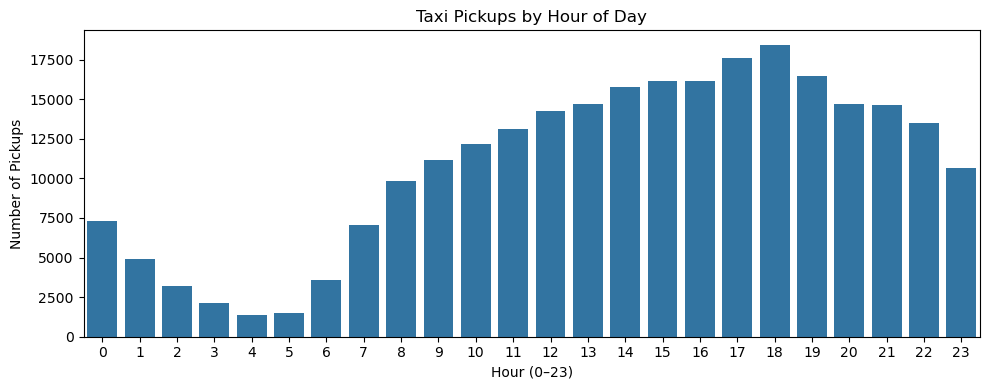

In [81]:
# Prepare data for temporal analysis
eda_df = df_cleaned_outliers.copy()

# Extract pickup hour from the pickup timestamp
eda_df["pickup_hour"] = eda_df["tpep_pickup_datetime"].dt.hour

# Calculate and plot hourly pickup counts
plt.figure(figsize=(10, 4))

sns.countplot(
    x="pickup_hour",
    data=eda_df,
    order=range(24)
)

plt.title("Taxi Pickups by Hour of Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Number of Pickups")
plt.tight_layout()
plt.show()

**Hourly Taxi Pickup Analysis**

The hourly pickup distribution shows clear variation in taxi demand throughout the day. Pickup activity is lowest during the early morning hours, particularly around 4–5 AM, and begins increasing from approximately 6 AM. Demand remains relatively high throughout the afternoon and reaches its highest level around 6 PM. Following the evening peak, pickup activity gradually declines.

These patterns suggest that taxi availability and driver scheduling could be aligned with periods of higher observed demand. Since the analysis uses a sample of the NYC Yellow Taxi dataset, the results describe the sampled trips rather than complete citywide pickup volumes.

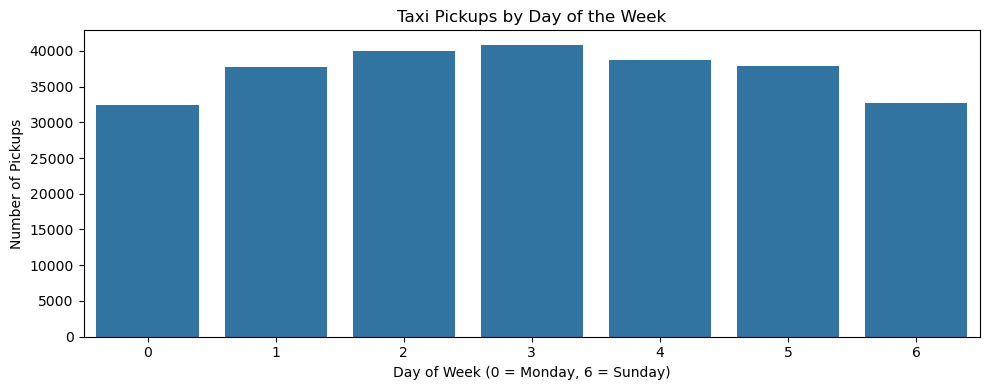

In [82]:
# Analyze taxi pickups by day of the week
eda_df["pickup_dayofweek"] = (
    eda_df["tpep_pickup_datetime"].dt.dayofweek
)

plt.figure(figsize=(10, 4))

sns.countplot(
    x="pickup_dayofweek",
    data=eda_df,
    order=range(7)
)

plt.title("Taxi Pickups by Day of the Week")
plt.xlabel("Day of Week (0 = Monday, 6 = Sunday)")
plt.ylabel("Number of Pickups")
plt.tight_layout()
plt.show()

**Taxi Pickup Analysis by Day of the Week**

The distribution of taxi pickups varies across the week. Thursday records the highest pickup activity, followed by Wednesday and Friday. Pickup activity is comparatively lower on Sunday and Monday, while Saturday shows a decline from weekday levels.

These findings suggest that fleet allocation and driver scheduling could account for differences in observed demand across weekdays and weekends. The results describe the sampled NYC Yellow Taxi trips and should not be interpreted as complete citywide pickup totals.

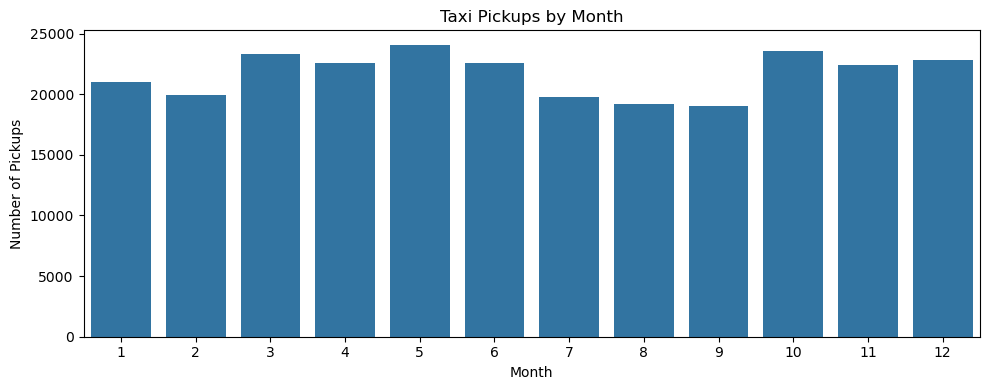

In [83]:
# Analyze taxi pickups by month
eda_df["pickup_month"] = (
    eda_df["tpep_pickup_datetime"].dt.month
)

plt.figure(figsize=(10, 4))

sns.countplot(
    x="pickup_month",
    data=eda_df,
    order=range(1, 13)
)

plt.title("Taxi Pickups by Month")
plt.xlabel("Month")
plt.ylabel("Number of Pickups")
plt.tight_layout()
plt.show()

**Monthly Taxi Pickup Analysis**

The monthly distribution shows variation in pickup activity throughout 2023. May records the highest pickup count, while September records the lowest. Pickup activity declines from May through September before recovering noticeably in October. November shows a slight decline, followed by a modest increase in December.

These patterns may help inform monthly fleet planning and driver scheduling. However, the analysis describes the sampled NYC Yellow Taxi trips, and the observed differences do not by themselves establish the causes of monthly demand variation.

#### Financial Analysis


In [84]:
# Summarize key financial and trip variables in the current dataset
cols_to_check = [
    "fare_amount",
    "tip_amount",
    "total_amount",
    "trip_distance"
]

for col in cols_to_check:
    print(f"\n{col}:")
    print("Total entries:", df_cleaned_outliers[col].shape[0])
    print("Missing values:", df_cleaned_outliers[col].isna().sum())
    print("Zero values:", (df_cleaned_outliers[col] == 0).sum())
    print("Negative values:", (df_cleaned_outliers[col] < 0).sum())
    print("Mean:", round(df_cleaned_outliers[col].mean(), 2))
    print("Median:", round(df_cleaned_outliers[col].median(), 2))


fare_amount:
Total entries: 260301
Missing values: 0
Zero values: 0
Negative values: 0
Mean: 19.73
Median: 13.5

tip_amount:
Total entries: 260301
Missing values: 0
Zero values: 56781
Negative values: 0
Mean: 3.58
Median: 2.88

total_amount:
Total entries: 260301
Missing values: 0
Zero values: 0
Negative values: 0
Mean: 28.86
Median: 21.0

trip_distance:
Total entries: 260301
Missing values: 0
Zero values: 0
Negative values: 0
Mean: 3.52
Median: 1.8


**Initial Financial and Trip-Variable Assessment**

The current analytical dataset contains 260,301 trips. The average fare amount is $19.73, compared with a median of $13.50. The average total amount is $28.86, while the median is $21.00. These differences suggest right-skewed distributions, where a relatively small number of higher-value trips may influence the averages.

The average trip distance is 3.52 miles, compared with a median of 1.80 miles, also suggesting a right-skewed distribution. The tip amount has a mean of $3.58 and a median of $2.88. A total of 56,781 trips have zero recorded tips. These observations have been retained because a zero tip is not, by itself, evidence of an invalid trip.


#### Filtered Financial Analysis


In [85]:
# Create a dataset excluding trips with zero tips
df_no_zeros = df_cleaned_outliers[
    (df_cleaned_outliers["fare_amount"] > 0) &
    (df_cleaned_outliers["total_amount"] > 0) &
    (df_cleaned_outliers["trip_distance"] > 0) &
    (df_cleaned_outliers["tip_amount"] > 0)
].copy()

print("Original rows:", len(df_cleaned_outliers))
print("Filtered rows:", len(df_no_zeros))
print("Rows excluded:", len(df_cleaned_outliers) - len(df_no_zeros))
print(
    "Percentage excluded:",
    round(
        (len(df_cleaned_outliers) - len(df_no_zeros))
        / len(df_cleaned_outliers) * 100,
        2
    ),
    "%"
)

Original rows: 260301
Filtered rows: 203520
Rows excluded: 56781
Percentage excluded: 21.81 %


**Filtered Financial Analysis**

The filtering process reduced the dataset from 260,301 to 203,520 trips, excluding 56,781 records (21.81%). Since fare amounts, total amounts, and trip distances contained no zero values, all excluded records had zero recorded tips.

This filtered dataset is intended for analyses that specifically examine trips with positive tips. Zero-tip trips have not been considered invalid; they remain in the primary analytical dataset because they are relevant to understanding overall trip activity and tipping behavior. Consequently, the filtered dataset will not be used as a replacement for the full dataset in general revenue or trip-level analyses.


#### Monthly Revenue Trends


In [87]:
# Calculate monthly revenue using the full analytical dataset
eda_df["pickup_month"] = (
    eda_df["tpep_pickup_datetime"].dt.month
)

monthly_revenue = (
    eda_df.groupby("pickup_month")["total_amount"]
    .sum()
    .reset_index()
)

monthly_revenue.columns = ["month", "total_revenue"]

display(monthly_revenue)

,month,total_revenue
0,1,571477.68
1,2,539662.46
2,3,661514.96
3,4,646785.60
4,5,707330.42
5,6,663945.34
6,7,566867.14
7,8,559962.93
8,9,572612.46
9,10,695358.14


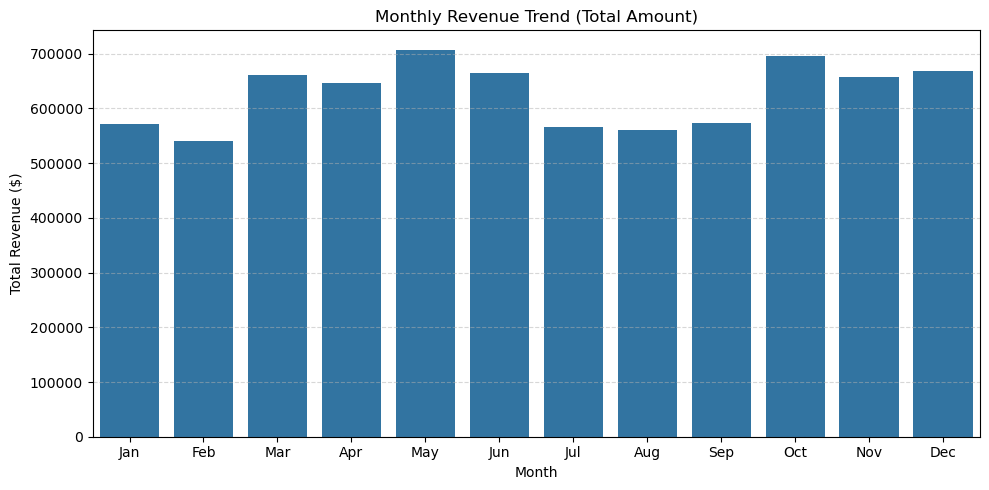

In [88]:
# Plot monthly revenue
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_revenue,
    x="month",
    y="total_revenue"
)

plt.title("Monthly Revenue Trend (Total Amount)")
plt.xlabel("Month")
plt.ylabel("Total Revenue ($)")
plt.xticks(
    ticks=range(12),
    labels=month_labels
)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Monthly Revenue Trends**

Monthly revenue varied throughout 2023. May recorded the highest revenue at $707,330.42, while February recorded the lowest at $539,662.46. Revenue declined after May, reaching a lower level in July and August before recovering in September. October showed a substantial increase, followed by a decline in November and a modest recovery in December.

These fluctuations indicate variation in the total recorded trip amounts across months. The results can help identify periods of relatively high and low activity within the sample. However, the figures represent revenue totals from the sampled trips and should not be interpreted as complete NYC Yellow Taxi system revenue.


#### Quarterly Revenue Contribution


In [91]:

# Calculate quarterly revenue
eda_df["quarter"] = eda_df["tpep_pickup_datetime"].dt.quarter

quarterly_revenue = (
    eda_df.groupby("quarter")["total_amount"]
    .sum()
    .reset_index()
)

# Calculate each quarter's percentage of annual revenue
quarterly_revenue["revenue_percent"] = (
    quarterly_revenue["total_amount"]
    / quarterly_revenue["total_amount"].sum()
    * 100
)

quarterly_revenue["quarter"] = "Q" + quarterly_revenue["quarter"].astype(str)

display(quarterly_revenue.round(2))



,quarter,total_amount,revenue_percent
0,Q1,1772655.10,23.60
1,Q2,2018061.36,26.87
2,Q3,1699442.53,22.63
3,Q4,2021139.91,26.91


**Quarterly Revenue Contribution**

Quarterly revenue analysis shows that Q4 contributed the largest share of recorded revenue at 26.91%, closely followed by Q2 at 26.87%. Q3 contributed the smallest share at 22.63%, while Q1 accounted for 23.60%.

The results indicate that recorded revenue was relatively higher in Q2 and Q4 than in Q1 and Q3. These findings may help identify seasonal patterns in the sampled trips, although further analysis would be required to establish the causes of these differences.


#### Trip Distance and Fare Relationship


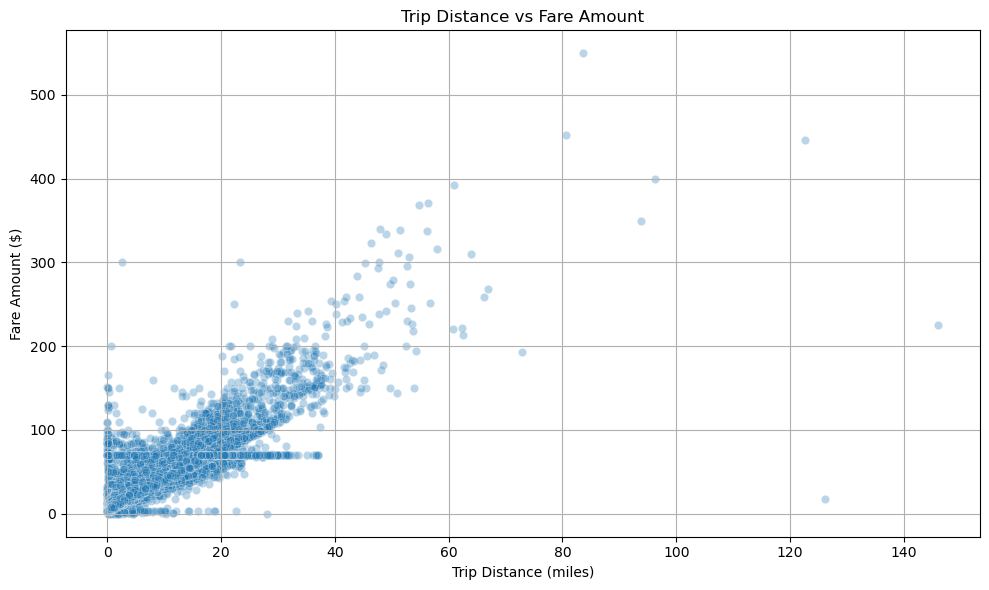

Correlation between trip distance and fare amount: 0.945


In [92]:

# Plot trip distance against fare amount
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cleaned_outliers,
    x="trip_distance",
    y="fare_amount",
    alpha=0.3
)

plt.title("Trip Distance vs Fare Amount")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Fare Amount ($)")
plt.grid(True)
plt.tight_layout()
plt.show()

# Calculate the correlation
correlation = df_cleaned_outliers["trip_distance"].corr(
    df_cleaned_outliers["fare_amount"]
)

print("Correlation between trip distance and fare amount:", round(correlation, 3))



**Trip Distance and Fare Relationship**

The scatter plot shows a strong positive relationship between trip distance and fare amount, with a Pearson correlation coefficient of 0.945. In general, longer trips are associated with higher fares. Most observations are concentrated among shorter trips with comparatively lower fares, while a smaller number of longer trips have substantially higher fares.

Although trip distance is strongly associated with fare amount, it does not fully explain fare variation. Other factors, including trip duration, rate codes, and applicable charges, may also influence the fare. Some unusual observations remain visible and should be interpreted cautiously rather than automatically classified as errors.


#### Relationships Between Fares, Duration, Passengers, and Tips


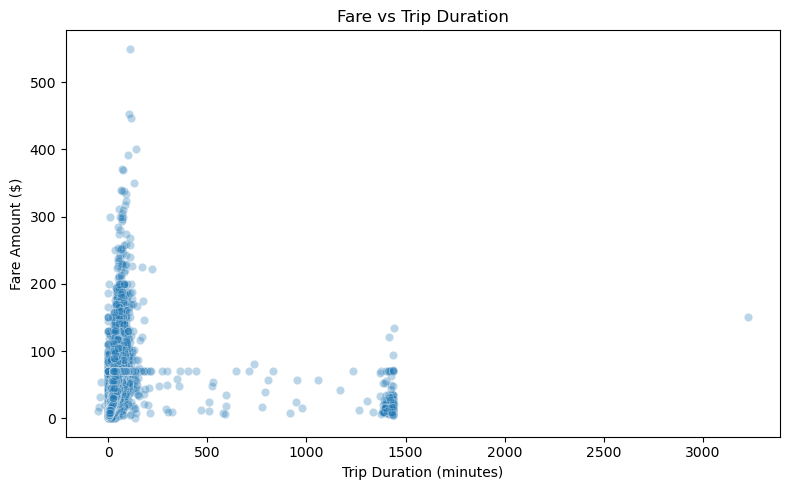

Correlation between fare and trip duration: 0.283


In [94]:
# Calculate trip duration in minutes
eda_df = df_cleaned_outliers.copy()

eda_df["trip_duration"] = (
    eda_df["tpep_dropoff_datetime"]
    - eda_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Plot fare amount against trip duration
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=eda_df,
    x="trip_duration",
    y="fare_amount",
    alpha=0.3
)

plt.title("Fare vs Trip Duration")
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Fare Amount ($)")
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = eda_df["trip_duration"].corr(
    eda_df["fare_amount"]
)

print("Correlation between fare and trip duration:", round(correlation, 3))

**Fare and Trip Duration Relationship**

The scatter plot shows a weak positive linear relationship between trip duration and fare amount, with a Pearson correlation coefficient of 0.283. Fare amounts vary considerably among trips with similar durations, suggesting that duration alone does not explain fare variation well.

A small number of observations have exceptionally long recorded durations, including trips lasting more than 1,000 minutes. These records may affect the correlation and require further investigation before conclusions about the relationship between duration and fare are drawn.


In [95]:
# Summarize trip durations
print("Minimum duration:", eda_df["trip_duration"].min())
print("Median duration:", eda_df["trip_duration"].median())
print("Maximum duration:", eda_df["trip_duration"].max())

print(
    "Trips lasting over 3 hours:",
    (eda_df["trip_duration"] > 180).sum()
)

print(
    "Trips lasting over 24 hours:",
    (eda_df["trip_duration"] > 1440).sum()
)

print(
    "Trips with negative duration:",
    (eda_df["trip_duration"] < 0).sum()
)

Minimum duration: -49.55
Median duration: 12.733333333333333
Maximum duration: 3225.1666666666665
Trips lasting over 3 hours: 230
Trips lasting over 24 hours: 1
Trips with negative duration: 19


In [96]:
# Inspect trips lasting over 3 hours
long_trips = eda_df[eda_df["trip_duration"] > 180]

display(
    long_trips[
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "trip_duration",
            "trip_distance",
            "fare_amount",
            "total_amount"
        ]
    ].sort_values("trip_duration", ascending=False).head(10)
)

# Inspect trips with negative duration
negative_trips = eda_df[eda_df["trip_duration"] < 0]

display(
    negative_trips[
        [
            "tpep_pickup_datetime",
            "tpep_dropoff_datetime",
            "trip_duration",
            "trip_distance",
            "fare_amount",
            "total_amount"
        ]
    ]
)

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration,trip_distance,fare_amount,total_amount
174089,2023-09-04 01:17:17,2023-09-06 07:02:27,3225.166667,2.12,150.0,163.75
97879,2023-02-17 13:40:57,2023-02-18 13:40:32,1439.583333,29.93,135.0,155.30
201834,2023-10-14 21:52:07,2023-10-15 21:51:32,1439.416667,2.40,21.2,31.44
95815,2023-02-14 18:00:40,2023-02-15 17:59:39,1438.983333,4.23,28.2,39.90
71563,2023-08-08 13:47:46,2023-08-09 13:46:43,1438.950000,1.73,19.1,23.10
208412,2023-10-23 13:00:00,2023-10-24 12:58:53,1438.883333,1.88,16.3,21.32
57080,2023-06-17 11:49:31,2023-06-18 11:48:21,1438.833333,10.45,47.8,65.32
18070,2023-01-27 17:13:05,2023-01-28 17:11:54,1438.816667,15.84,70.0,85.55
39596,2023-03-25 17:13:15,2023-03-26 17:11:54,1438.650000,0.36,5.1,10.46
51828,2023-06-10 16:35:43,2023-06-11 16:34:18,1438.583333,5.96,33.8,37.80


,tpep_pickup_datetime,tpep_dropoff_datetime,trip_duration,trip_distance,fare_amount,total_amount
27399,2023-03-09 14:03:54,2023-03-09 14:03:27,-0.450000,13.20,57.45,58.25
32143,2023-03-15 19:03:26,2023-03-15 19:03:13,-0.216667,1.24,35.50,38.00
48156,2023-06-06 06:06:18,2023-06-06 06:06:15,-0.050000,8.12,27.56,28.36
52911,2023-06-12 07:06:52,2023-06-12 07:06:28,-0.400000,2.19,25.41,26.21
72287,2023-08-09 14:08:52,2023-08-09 14:08:17,-0.583333,1.39,24.20,25.00
85635,2023-08-31 11:40:00,2023-08-31 11:24:26,-15.566667,1.80,19.50,21.00
92644,2023-02-10 10:02:59,2023-02-10 10:02:05,-0.900000,5.09,26.20,27.00
95037,2023-02-13 15:02:50,2023-02-13 15:02:24,-0.433333,7.61,57.50,60.00
105517,2023-02-28 12:02:45,2023-02-28 12:02:02,-0.716667,4.81,30.20,31.00
107997,2023-04-03 19:04:46,2023-04-03 19:04:15,-0.516667,7.44,26.59,27.39


In [97]:
# Create a separate dataset for duration analysis
duration_df = df_cleaned_outliers.copy()

# Calculate trip duration in minutes
duration_df["trip_duration"] = (
    duration_df["tpep_dropoff_datetime"]
    - duration_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Keep trips with positive durations of no more than 3 hours
duration_df = duration_df[
    (duration_df["trip_duration"] > 0) &
    (duration_df["trip_duration"] <= 180)
].copy()

print("Original trips:", len(df_cleaned_outliers))
print("Trips retained for duration analysis:", len(duration_df))
print("Trips excluded from duration analysis:",
      len(df_cleaned_outliers) - len(duration_df))

Original trips: 260301
Trips retained for duration analysis: 260046
Trips excluded from duration analysis: 255


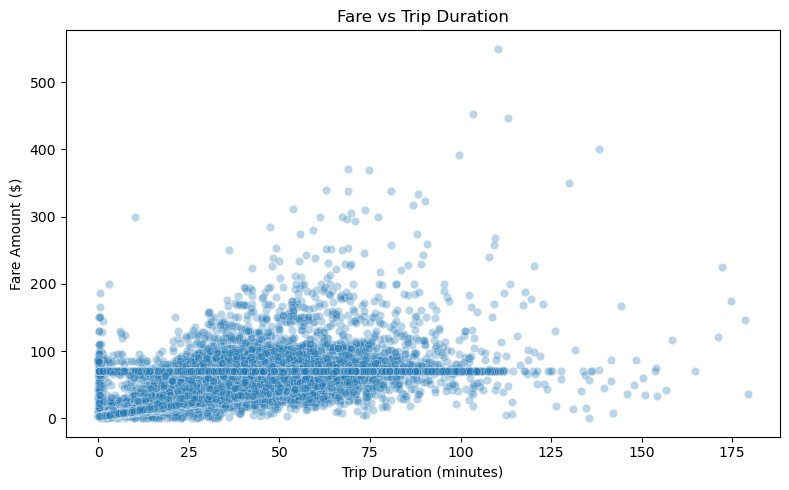

Correlation between fare and trip duration: 0.845


In [98]:
# Plot fare against valid trip duration
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=duration_df,
    x="trip_duration",
    y="fare_amount",
    alpha=0.3
)

plt.title("Fare vs Trip Duration")
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Fare Amount ($)")
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = duration_df["trip_duration"].corr(
    duration_df["fare_amount"]
)

print("Correlation between fare and trip duration:", round(correlation, 3))

**Fare and Trip Duration Relationship**

Initially, the correlation between trip duration and fare amount was 0.283. Further investigation identified 19 trips with negative durations and 230 trips lasting more than three hours. These 255 records were excluded from this duration-specific analysis, leaving 260,046 trips with durations greater than zero and no more than 180 minutes.

After filtering, the correlation increased to 0.845, indicating a strong positive linear relationship between trip duration and fare amount in the retained dataset. This change demonstrates that extreme and invalid duration records can substantially affect correlation analysis. The three-hour threshold is an analytical assumption, and the excluded records were not removed from the primary dataset.


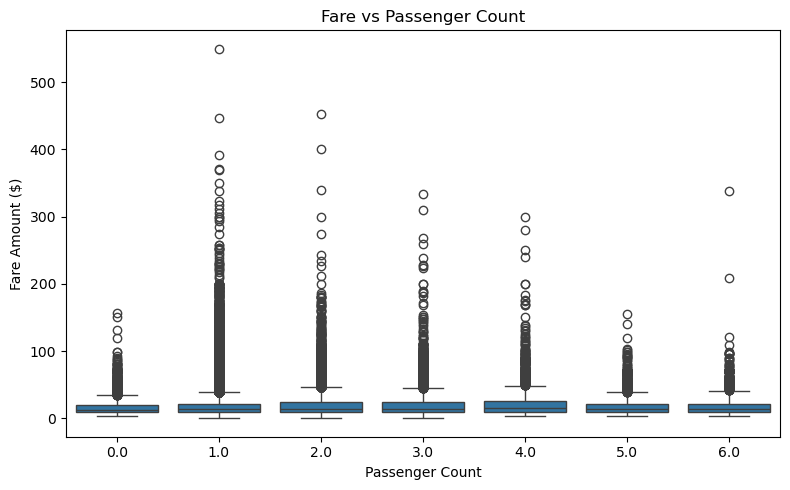

Correlation between fare and passenger count: 0.049


In [99]:
# Plot fare amount against passenger count
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_cleaned_outliers,
    x="passenger_count",
    y="fare_amount"
)

plt.title("Fare vs Passenger Count")
plt.xlabel("Passenger Count")
plt.ylabel("Fare Amount ($)")
plt.tight_layout()
plt.show()

# Calculate correlation using records with known passenger counts
passenger_data = df_cleaned_outliers.dropna(
    subset=["passenger_count", "fare_amount"]
)

correlation = passenger_data["fare_amount"].corr(
    passenger_data["passenger_count"]
)

print("Correlation between fare and passenger count:", round(correlation, 3))

**Fare and Passenger Count Relationship**

The box plot shows that fare amounts have broadly similar distributions across passenger-count categories, although high-value outliers occur in each group. The Pearson correlation between passenger count and fare amount is 0.049, indicating an extremely weak linear relationship.

These results suggest that passenger count alone has little linear association with fare amount in the sampled trips. Other factors, such as trip distance, duration, and applicable rates, may be more relevant to fare variation. Records with zero passenger counts have been retained because the available evidence does not establish that these observations are invalid.


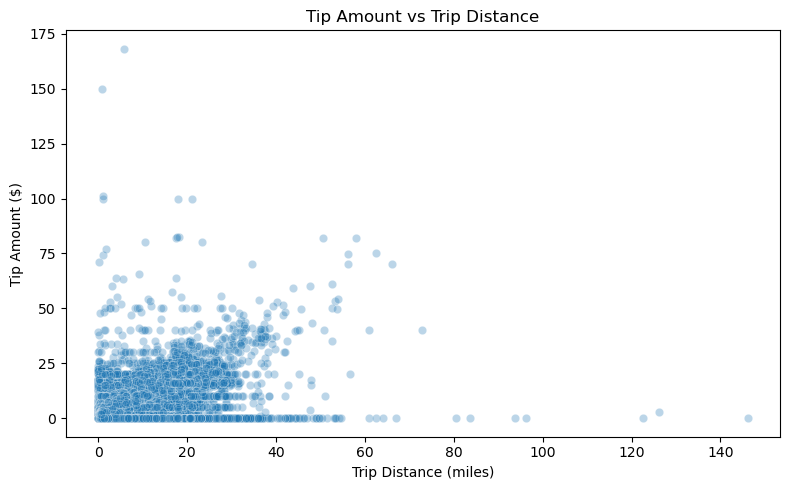

Correlation between tip amount and trip distance: 0.589


In [100]:
# Plot tip amount against trip distance
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_cleaned_outliers,
    x="trip_distance",
    y="tip_amount",
    alpha=0.3
)

plt.title("Tip Amount vs Trip Distance")
plt.xlabel("Trip Distance (miles)")
plt.ylabel("Tip Amount ($)")
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = df_cleaned_outliers["trip_distance"].corr(
    df_cleaned_outliers["tip_amount"]
)

print("Correlation between tip amount and trip distance:", round(correlation, 3))

**Tip Amount and Trip Distance Relationship**

The scatter plot shows a moderate positive relationship between trip distance and tip amount, with a Pearson correlation coefficient of 0.589. Longer trips generally tend to have higher tips, although considerable variation exists. Most recorded tips are below $25, and zero tips occur across different trip distances.

Compared with the correlation between trip distance and fare amount (0.945), the relationship between distance and tips is weaker. This suggests that trip distance alone does not fully explain tipping behavior. Other factors, including fare amount, payment method, and passenger preferences, may contribute to the observed variation.


#### Payment-Type Distribution


payment_type
0      7129
1    207283
2     43255
3       941
4      1693
Name: count, dtype: int64


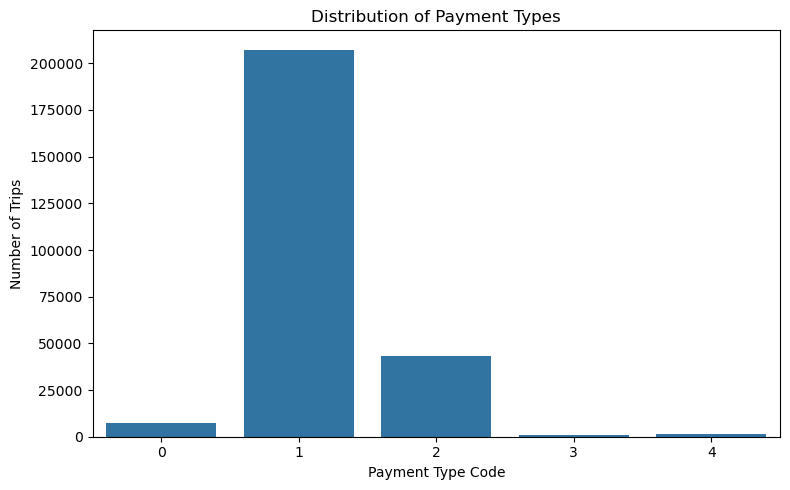

In [101]:
# Count trips by payment type
payment_counts = (
    df_cleaned_outliers["payment_type"]
    .value_counts()
    .sort_index()
)

print(payment_counts)

# Plot payment-type distribution
plt.figure(figsize=(8, 5))

sns.barplot(
    x=payment_counts.index.astype(str),
    y=payment_counts.values
)

plt.title("Distribution of Payment Types")
plt.xlabel("Payment Type Code")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

**Payment-Type Distribution**

The payment-type distribution is highly concentrated in code 1, which accounts for approximately 79.63% of the sampled trips. Code 2 represents approximately 16.61%, while code 0 accounts for 2.74%. Codes 3 and 4 occur much less frequently.

An earlier data-quality assessment found that all 7,129 records with payment type 0 also have missing values in passenger_count, RatecodeID, store_and_fwd_flag, and airport_fee. This shared missingness pattern is worth documenting, although it does not establish that the payment-type values are invalid. Payment-type labels should be assigned using the applicable NYC TLC data dictionary.


#### Geographic Analysis


In [102]:
!pip install geopandas

#### Taxi-Zone Boundaries


In [104]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import os

# Load NYC taxi-zone boundaries using the full folder path
zones_path = r"C:\Users\Gill\Downloads\Datasets and Dictionary-NYC (1)\Datasets and Dictionary\taxi_zones\taxi_zones.shp"

zones = gpd.read_file(zones_path)

# Inspect the zone data
display(zones.head())

print("Number of zones:", len(zones))
print("Coordinate reference system:", zones.crs)
print("Columns:", zones.columns.tolist())

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Number of zones: 263
Coordinate reference system: EPSG:2263
Columns: ['OBJECTID', 'Shape_Leng', 'Shape_Area', 'zone', 'LocationID', 'borough', 'geometry']


Taxi-zone boundaries can be joined to trip records through the corresponding location IDs, enabling geographic aggregation and mapping.


In [105]:
# Join trip records to their pickup zones
df_merged_pickup = df_cleaned_outliers.merge(
    zones[["LocationID", "zone", "borough"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left"
)

# Rename columns for clarity
df_merged_pickup.rename(
    columns={
        "zone": "PU_zone",
        "borough": "PU_borough"
    },
    inplace=True
)

# Remove the duplicate join key
df_merged_pickup.drop(columns=["LocationID"], inplace=True)

# Validate the join
print("Original trip records:", len(df_cleaned_outliers))
print("Records after pickup-zone join:", len(df_merged_pickup))
print("Missing pickup-zone names:", df_merged_pickup["PU_zone"].isna().sum())

display(
    df_merged_pickup[
        ["PULocationID", "PU_zone", "PU_borough"]
    ].head()
)

Original trip records: 260301
Records after pickup-zone join: 260314
Missing pickup-zone names: 2326


,PULocationID,PU_zone,PU_borough
0,144,Little Italy/NoLiTa,Manhattan
1,79,East Village,Manhattan
2,48,Clinton East,Manhattan
3,68,East Chelsea,Manhattan
4,48,Clinton East,Manhattan


In [106]:
# Check whether taxi-zone LocationIDs are unique
print("Total zone records:", len(zones))
print("Unique LocationIDs:", zones["LocationID"].nunique())
print("Duplicate LocationIDs:", zones["LocationID"].duplicated().sum())

# Display any duplicate LocationIDs
display(
    zones[zones["LocationID"].duplicated(keep=False)]
    [["LocationID", "zone", "borough"]]
    .sort_values("LocationID")
)

Total zone records: 263
Unique LocationIDs: 260
Duplicate LocationIDs: 3


,LocationID,zone,borough
55,56,Corona,Queens
56,56,Corona,Queens
102,103,Governor's Island/Ellis Island/Liberty Island,Manhattan
103,103,Governor's Island/Ellis Island/Liberty Island,Manhattan
104,103,Governor's Island/Ellis Island/Liberty Island,Manhattan


In [107]:
# Keep one zone record per LocationID
zones_unique = zones.drop_duplicates(
    subset="LocationID"
).copy()

print("Original zone records:", len(zones))
print("Zone records after deduplication:", len(zones_unique))
print("Unique LocationIDs:", zones_unique["LocationID"].nunique())
print("Remaining duplicate IDs:", zones_unique["LocationID"].duplicated().sum())

Original zone records: 263
Zone records after deduplication: 260
Unique LocationIDs: 260
Remaining duplicate IDs: 0


In [108]:
df_merged_pickup = df_cleaned_outliers.merge(
    zones_unique[["LocationID", "zone", "borough"]],
    left_on="PULocationID",
    right_on="LocationID",
    how="left",
    validate="many_to_one"
)

df_merged_pickup.rename(
    columns={
        "zone": "PU_zone",
        "borough": "PU_borough"
    },
    inplace=True
)

df_merged_pickup.drop(columns=["LocationID"], inplace=True)

print("Original trip records:", len(df_cleaned_outliers))
print("Records after pickup-zone join:", len(df_merged_pickup))
print("Missing pickup-zone names:", df_merged_pickup["PU_zone"].isna().sum())

Original trip records: 260301
Records after pickup-zone join: 260301
Missing pickup-zone names: 2326


In [109]:
# Identify pickup location IDs without a matching taxi-zone name
unmatched_pickups = (
    df_merged_pickup.loc[
        df_merged_pickup["PU_zone"].isna(),
        "PULocationID"
    ]
    .value_counts()
    .rename_axis("PULocationID")
    .reset_index(name="trip_count")
)

print("Number of unmatched pickup location IDs:", len(unmatched_pickups))
print("Trips with unmatched pickup locations:", unmatched_pickups["trip_count"].sum())

display(unmatched_pickups.head(20))

Number of unmatched pickup location IDs: 2
Trips with unmatched pickup locations: 2326


,PULocationID,trip_count
0,264,2208
1,265,118


**Handling Unmatched Pickup Locations**

The pickup-zone join preserved all 260,301 trip records without duplicating rows. However, 2,326 trips (approximately 0.89% of the dataset) could not be matched to a taxi-zone polygon. These records correspond to pickup location IDs 264 (2,208 trips) and 265 (118 trips), which are absent from the geographic reference data.

These trips are retained in the dataset because an unmatched geographic identifier does not, by itself, establish that a trip is invalid. However, they cannot be assigned to a mapped taxi zone using the available shapefile. Their exclusion from zone-level geographic summaries, where necessary, will be documented.


In [110]:
# Count trips by pickup location
pickup_counts = (
    df_cleaned_outliers["PULocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="pickup_trip_count")
)

# Count trips by drop-off location
dropoff_counts = (
    df_cleaned_outliers["DOLocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="dropoff_trip_count")
)

print("Total pickup records:", pickup_counts["pickup_trip_count"].sum())
print("Total drop-off records:", dropoff_counts["dropoff_trip_count"].sum())

Total pickup records: 260301
Total drop-off records: 260301


#### Prepare Zone-Level Trip Counts for Mapping


In [111]:
# Count pickups by zone
pickup_counts = (
    df_cleaned_outliers["PULocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="pickup_count")
)

# Count drop-offs by zone
dropoff_counts = (
    df_cleaned_outliers["DOLocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="dropoff_count")
)

# Combine pickup and drop-off counts
trip_counts = pickup_counts.merge(
    dropoff_counts,
    on="LocationID",
    how="outer"
).fillna(0)

# Calculate total activity per zone
trip_counts["total_trips"] = (
    trip_counts["pickup_count"] + trip_counts["dropoff_count"]
)

# Join counts to geographic boundaries
zones_merged = zones_unique.merge(
    trip_counts,
    on="LocationID",
    how="left"
)

# Zones with no observed trips receive zero counts
count_columns = ["pickup_count", "dropoff_count", "total_trips"]
zones_merged[count_columns] = zones_merged[count_columns].fillna(0)

print("Number of mapped zones:", len(zones_merged))
print("Total pickup counts across mapped zones:", int(zones_merged["pickup_count"].sum()))
print("Total drop-off counts across mapped zones:", int(zones_merged["dropoff_count"].sum()))

display(
    zones_merged[
        ["LocationID", "zone", "borough", "pickup_count", "dropoff_count", "total_trips"]
    ].sort_values("total_trips", ascending=False).head(10)
)

Number of mapped zones: 260
Total pickup counts across mapped zones: 257975
Total drop-off counts across mapped zones: 256957


,LocationID,zone,borough,pickup_count,dropoff_count,total_trips
233,237,Upper East Side South,Manhattan,12312.0,11050.0,23362.0
232,236,Upper East Side North,Manhattan,10966.0,11803.0,22769.0
157,161,Midtown Center,Manhattan,12132.0,10302.0,22434.0
158,162,Midtown East,Manhattan,9342.0,7403.0,16745.0
226,230,Times Sq/Theatre District,Manhattan,8678.0,7954.0,16632.0
128,132,JFK Airport,Queens,13444.0,3058.0,16502.0
138,142,Lincoln Square East,Manhattan,8586.0,7357.0,15943.0
166,170,Murray Hill,Manhattan,7667.0,7800.0,15467.0
182,186,Penn Station/Madison Sq West,Manhattan,8884.0,5640.0,14524.0
235,239,Upper West Side South,Manhattan,7200.0,7294.0,14494.0


#### Pickup-Activity Choropleth


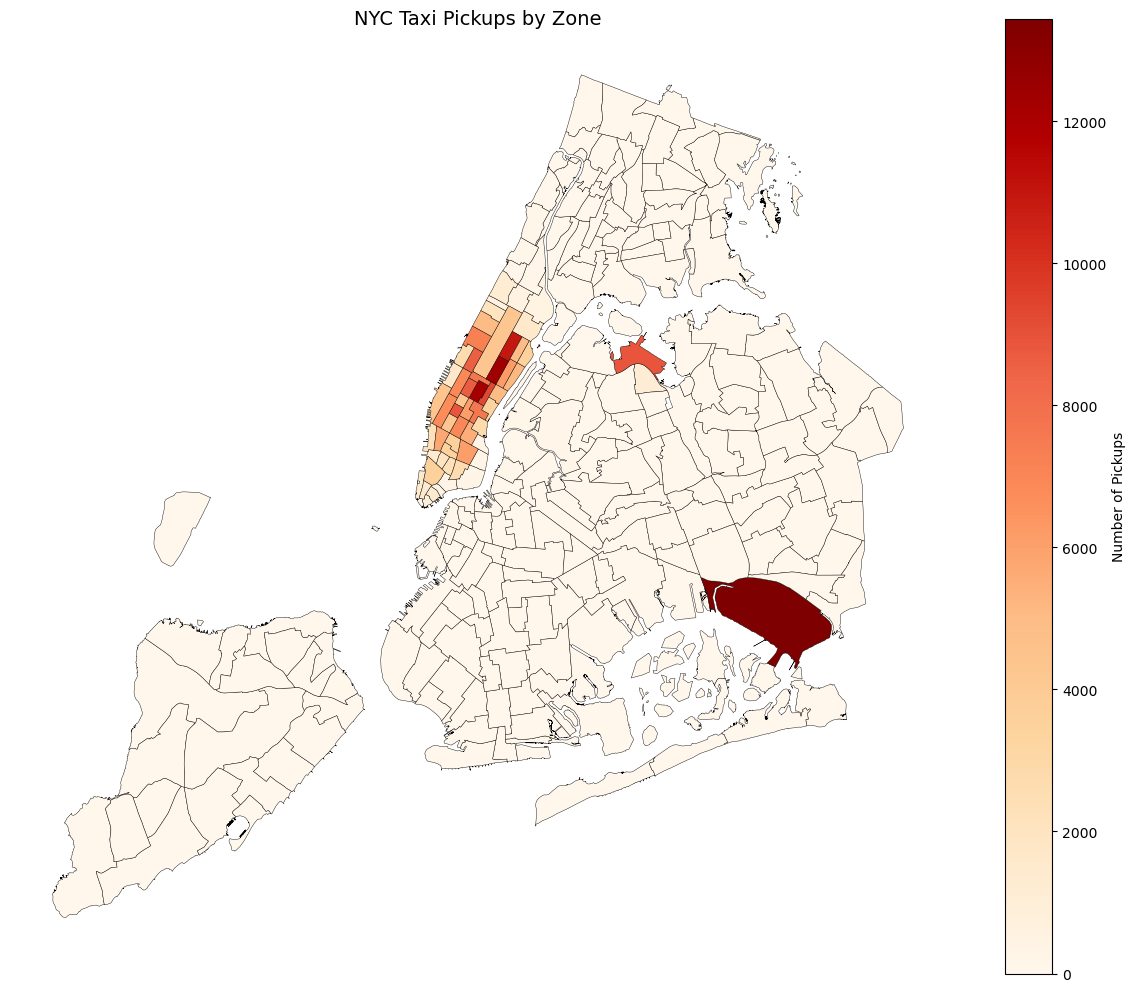

In [112]:
# Plot pickup activity by taxi zone
fig, ax = plt.subplots(figsize=(12, 10))

zones_merged.plot(
    column="pickup_count",
    ax=ax,
    cmap="OrRd",
    legend=True,
    legend_kwds={"label": "Number of Pickups", "orientation": "vertical"},
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={"color": "lightgrey"}
)

ax.set_title("NYC Taxi Pickups by Zone", fontsize=14)
ax.set_axis_off()
plt.tight_layout()
plt.show()

**Pickup Activity by Taxi Zone**

The choropleth map shows that sampled taxi pickups are concentrated in Manhattan, particularly around Midtown and the Upper East Side, while the JFK Airport zone also stands out as a major pickup hotspot. Many zones in the outer boroughs show comparatively lower pickup activity.

This geographic variation suggests that taxi demand differs substantially across locations. From an operational perspective, these patterns may help identify areas where driver availability and fleet allocation deserve closer examination. However, the findings represent the sampled 2023 records and should not be interpreted as complete citywide trip totals.


In [113]:
# Display the 10 zones with the most pickups
top_pickup_zones = (
    zones_merged
    .sort_values("pickup_count", ascending=False)
    [["zone", "borough", "pickup_count"]]
    .head(10)
)

display(top_pickup_zones)

,zone,borough,pickup_count
128,JFK Airport,Queens,13444.0
233,Upper East Side South,Manhattan,12312.0
157,Midtown Center,Manhattan,12132.0
232,Upper East Side North,Manhattan,10966.0
158,Midtown East,Manhattan,9342.0
182,Penn Station/Madison Sq West,Manhattan,8884.0
134,LaGuardia Airport,Queens,8878.0
226,Times Sq/Theatre District,Manhattan,8678.0
138,Lincoln Square East,Manhattan,8586.0
159,Midtown North,Manhattan,7690.0


**Highest-Activity Pickup Zones**

JFK Airport recorded the highest number of pickups in the sampled dataset, with 13,344 trips. It was followed by Upper East Side South (12,312) and Midtown Center (12,132). Several other high-activity zones are located in Manhattan, including Upper East Side North, Midtown East, and the Times Square/Theatre District area. LaGuardia Airport also ranked among the ten busiest pickup zones.

These results highlight the importance of airport and central Manhattan locations in the sampled pickup activity. From an operational perspective, these areas may warrant closer examination when planning driver availability and fleet allocation. The rankings describe the sampled records and should not be treated as complete annual trip totals.


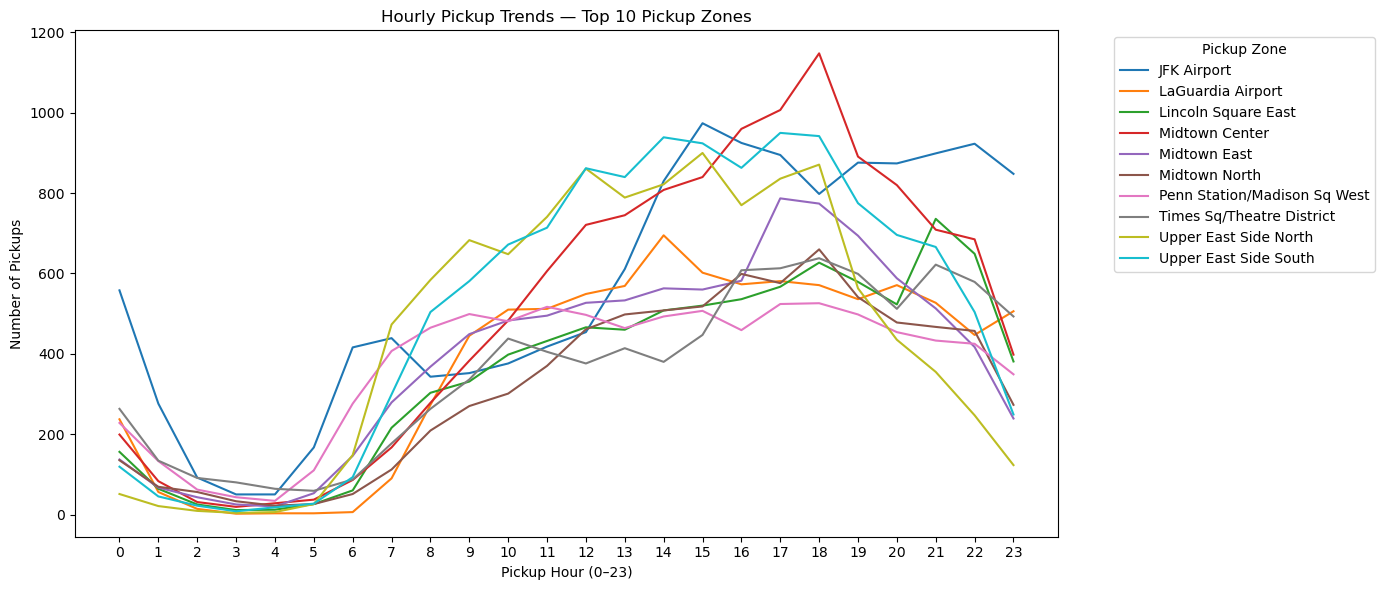

In [114]:
# Identify the 10 busiest pickup zones
top_pickup_zones = (
    df_merged_pickup["PU_zone"]
    .value_counts()
    .head(10)
    .index
)

# Keep trips belonging to those zones
pickup_trends = df_merged_pickup[
    df_merged_pickup["PU_zone"].isin(top_pickup_zones)
].copy()

# Extract pickup hour
pickup_trends["pickup_hour"] = (
    pickup_trends["tpep_pickup_datetime"].dt.hour
)

# Count pickups by zone and hour
pickup_trends = (
    pickup_trends.groupby(["PU_zone", "pickup_hour"])
    .size()
    .reset_index(name="num_pickups")
)

# Plot hourly trends
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=pickup_trends,
    x="pickup_hour",
    y="num_pickups",
    hue="PU_zone"
)

plt.title("Hourly Pickup Trends — Top 10 Pickup Zones")
plt.xlabel("Pickup Hour (0–23)")
plt.ylabel("Number of Pickups")
plt.xticks(range(24))
plt.legend(title="Pickup Zone", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Hourly Pickup Trends Across High-Activity Zones**

The hourly pickup chart shows that demand varies across both time and location. Pickup activity generally increases from the early morning, with many high-activity zones recording substantial demand throughout the afternoon and early evening. Peak activity differs by zone, indicating that the busiest locations do not necessarily share the same demand pattern.

JFK Airport also exhibits a pattern that differs from many Manhattan zones, including comparatively high activity around midnight. These differences suggest that zone-specific demand patterns may be useful when planning driver availability and fleet allocation. However, the chart represents sampled trips, so its counts should not be interpreted as complete hourly demand.


In [115]:
# Identify the 10 busiest drop-off zones
top_dropoff_zones = (
    df_cleaned_outliers["DOLocationID"]
    .value_counts()
    .head(10)
)

# Join the rankings to the zone reference data
top_dropoff_table = top_dropoff_zones.rename_axis(
    "LocationID"
).reset_index(name="dropoff_count")

top_dropoff_table = top_dropoff_table.merge(
    zones_unique[["LocationID", "zone", "borough"]],
    on="LocationID",
    how="left"
)

display(
    top_dropoff_table[
        ["zone", "borough", "dropoff_count"]
    ]
)

,zone,borough,dropoff_count
0,Upper East Side North,Manhattan,11803
1,Upper East Side South,Manhattan,11050
2,Midtown Center,Manhattan,10302
3,Times Sq/Theatre District,Manhattan,7954
4,Murray Hill,Manhattan,7800
5,Midtown East,Manhattan,7403
6,Lincoln Square East,Manhattan,7357
7,Upper West Side South,Manhattan,7294
8,Lenox Hill West,Manhattan,6836
9,Midtown North,Manhattan,6669


**Top Drop-Off Zones**

The drop-off analysis shows that all ten highest-activity destination zones in the sampled dataset are located in Manhattan. Upper East Side North recorded the highest number of drop-offs (11,803), followed by Upper East Side South (11,050) and Midtown Center (10,302). Other high-activity destinations include Times Square/Theatre District, Murray Hill, and Midtown East.

This concentration suggests that Manhattan is a major destination for the sampled taxi trips. These findings may help inform driver positioning and fleet planning, although drop-off counts alone do not establish whether drivers will find passengers for return trips.


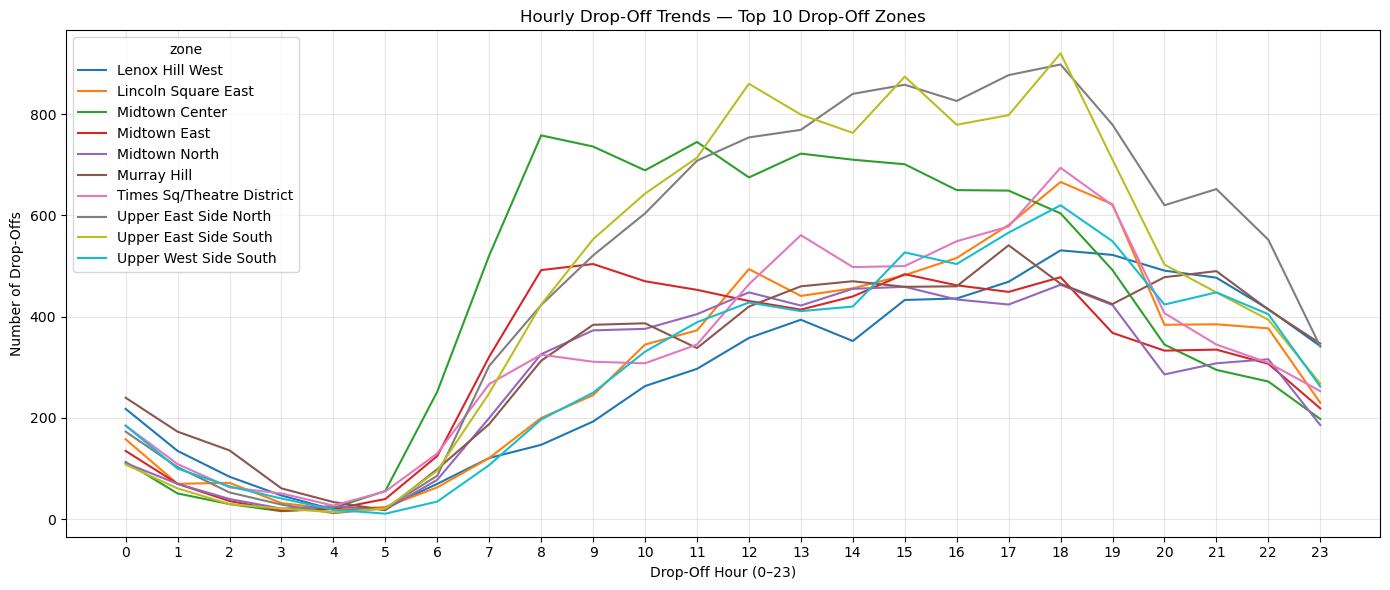

In [116]:
# Extract drop-off hour
df_eda = df_cleaned_outliers.copy()
df_eda["dropoff_hour"] = df_eda["tpep_dropoff_datetime"].dt.hour

# Keep the 10 busiest drop-off zones
top_zones = top_dropoff_table["LocationID"]

dropoff_hourly = df_eda[
    df_eda["DOLocationID"].isin(top_zones)
]

# Count drop-offs by hour and zone
dropoff_hourly = (
    dropoff_hourly
    .groupby(["dropoff_hour", "DOLocationID"])
    .size()
    .reset_index(name="dropoff_count")
)

# Add zone names
dropoff_hourly = dropoff_hourly.merge(
    zones_unique[["LocationID", "zone"]],
    left_on="DOLocationID",
    right_on="LocationID",
    how="left"
)

# Plot hourly trends
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=dropoff_hourly,
    x="dropoff_hour",
    y="dropoff_count",
    hue="zone"
)

plt.title("Hourly Drop-Off Trends — Top 10 Drop-Off Zones")
plt.xlabel("Drop-Off Hour (0–23)")
plt.ylabel("Number of Drop-Offs")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Hourly Drop-Off Trends in the Top 10 Destination Zones**

The hourly analysis shows that drop-off activity varies across the ten busiest destination zones. Activity is generally low during the early morning hours and increases from approximately 6:00 AM onward.

Midtown Center shows a pronounced morning increase, while Upper East Side North and Upper East Side South experience substantial activity through the afternoon. Several zones reach their highest observed drop-off counts between approximately 3:00 PM and 6:00 PM. Activity generally declines after 7:00 PM.

These patterns may help identify when popular destinations are likely to receive more passengers. However, the chart represents counts from the sampled dataset, so the results should be interpreted as patterns within the sample rather than complete annual trip totals.


In [117]:
# Count pickups and drop-offs by zone
pickup_counts = (
    df_cleaned_outliers["PULocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .rename("pickup_count")
)

dropoff_counts = (
    df_cleaned_outliers["DOLocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .rename("dropoff_count")
)

# Combine the counts
zone_ratios = pd.concat(
    [pickup_counts, dropoff_counts],
    axis=1
).fillna(0).reset_index()

# Calculate total observed activity
zone_ratios["total_activity"] = (
    zone_ratios["pickup_count"] + zone_ratios["dropoff_count"]
)

# Keep zones with at least 100 combined observations
zone_ratios = zone_ratios[
    zone_ratios["total_activity"] >= 100
].copy()

# Calculate pickup-to-drop-off ratio
zone_ratios["pickup_dropoff_ratio"] = (
    zone_ratios["pickup_count"] /
    zone_ratios["dropoff_count"].replace(0, np.nan)
)

# Add zone names and boroughs
zone_ratios = zone_ratios.merge(
    zones_unique[["LocationID", "zone", "borough"]],
    on="LocationID",
    how="left"
)

# Display the 10 highest and lowest ratios
print("Top 10 zones by pickup-to-drop-off ratio:")
display(
    zone_ratios.sort_values(
        "pickup_dropoff_ratio", ascending=False
    )[["zone", "borough", "pickup_count", "dropoff_count",
       "pickup_dropoff_ratio"]].head(10)
)

print("Bottom 10 zones by pickup-to-drop-off ratio:")
display(
    zone_ratios.sort_values(
        "pickup_dropoff_ratio", ascending=True
    )[["zone", "borough", "pickup_count", "dropoff_count",
       "pickup_dropoff_ratio"]].head(10)
)

Top 10 zones by pickup-to-drop-off ratio:


,zone,borough,pickup_count,dropoff_count,pickup_dropoff_ratio
48,East Elmhurst,Queens,1143.0,124.0,9.217742
0,JFK Airport,Queens,13444.0,3058.0,4.396337
6,LaGuardia Airport,Queens,8878.0,3287.0,2.700943
5,Penn Station/Madison Sq West,Manhattan,8884.0,5640.0,1.575177
31,Greenwich Village South,Manhattan,3510.0,2551.0,1.375931
27,Central Park,Manhattan,4259.0,3137.0,1.357667
18,West Village,Manhattan,5754.0,4363.0,1.318817
4,Midtown East,Manhattan,9342.0,7403.0,1.261921
26,Garment District,Manhattan,4303.0,3567.0,1.206336
25,Flatiron,Manhattan,4319.0,3613.0,1.195405


Bottom 10 zones by pickup-to-drop-off ratio:


,zone,borough,pickup_count,dropoff_count,pickup_dropoff_ratio
123,Newark Airport,EWR,5.0,724.0,0.006906
124,Windsor Terrace,Brooklyn,4.0,116.0,0.034483
120,Roosevelt Island,Manhattan,9.0,179.0,0.050279
122,Crown Heights South,Brooklyn,6.0,111.0,0.054054
121,Spuyten Duyvil/Kingsbridge,Bronx,6.0,103.0,0.058252
113,Prospect Heights,Brooklyn,16.0,237.0,0.067511
117,Inwood,Manhattan,13.0,184.0,0.070652
84,Greenpoint,Brooklyn,46.0,609.0,0.075534
119,Ridgewood,Queens,11.0,137.0,0.080292
114,Flushing,Queens,16.0,191.0,0.083770


**Pickup-to-Drop-Off Ratios by Zone**

The pickup-to-drop-off ratio reveals substantial differences in observed taxi activity across zones. East Elmhurst recorded the highest ratio (9.22), followed by JFK Airport (4.40) and LaGuardia Airport (2.70), indicating considerably more pickups than drop-offs in these locations within the sample.

Conversely, Newark Airport recorded the lowest ratio (0.007), with five pickups compared with 724 drop-offs. Several other zones also had substantially more drop-offs than pickups.

These differences identify locations where pickup and drop-off activity is uneven. They may help guide further investigation into geographic demand patterns and fleet positioning. However, the ratios do not directly measure taxi availability or establish the causes of the observed imbalances. Results are based on the sampled records, and ratios for zones with relatively few observations should be interpreted cautiously.


In [118]:
# Define overnight hours: 11 PM to 5 AM
night_hours = [23, 0, 1, 2, 3, 4, 5]

# Extract pickup and drop-off hours
df_night = df_cleaned_outliers.copy()

df_night["pickup_hour"] = df_night["tpep_pickup_datetime"].dt.hour
df_night["dropoff_hour"] = df_night["tpep_dropoff_datetime"].dt.hour

# Top 10 overnight pickup zones
night_pickups = (
    df_night[df_night["pickup_hour"].isin(night_hours)]
    ["PULocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="pickup_count")
    .head(10)
    .merge(
        zones_unique[["LocationID", "zone", "borough"]],
        on="LocationID",
        how="left"
    )
)

# Top 10 overnight drop-off zones
night_dropoffs = (
    df_night[df_night["dropoff_hour"].isin(night_hours)]
    ["DOLocationID"]
    .value_counts()
    .rename_axis("LocationID")
    .reset_index(name="dropoff_count")
    .head(10)
    .merge(
        zones_unique[["LocationID", "zone", "borough"]],
        on="LocationID",
        how="left"
    )
)

print("Top 10 Overnight Pickup Zones")
display(night_pickups[["zone", "borough", "pickup_count"]])

print("Top 10 Overnight Drop-Off Zones")
display(night_dropoffs[["zone", "borough", "dropoff_count"]])

Top 10 Overnight Pickup Zones


,zone,borough,pickup_count
0,East Village,Manhattan,2230
1,JFK Airport,Queens,2041
2,West Village,Manhattan,1787
3,Clinton East,Manhattan,1470
4,Lower East Side,Manhattan,1371
5,Greenwich Village South,Manhattan,1315
6,Times Sq/Theatre District,Manhattan,1184
7,Penn Station/Madison Sq West,Manhattan,959
8,Midtown South,Manhattan,899
9,East Chelsea,Manhattan,838


Top 10 Overnight Drop-Off Zones


,zone,borough,dropoff_count
0,East Village,Manhattan,1254
1,Clinton East,Manhattan,1055
2,Murray Hill,Manhattan,1009
3,Gramercy,Manhattan,936
4,Lenox Hill West,Manhattan,867
5,East Chelsea,Manhattan,835
6,Yorkville West,Manhattan,793
7,West Village,Manhattan,759
8,Times Sq/Theatre District,Manhattan,743
9,Upper East Side North,Manhattan,733


**Overnight Pickup and Drop-Off Activity**

During the selected overnight hours, East Village recorded the highest pickup count (2,230) and the highest drop-off count (1,254). JFK Airport ranked second for pickups, with 2,041 trips, while West Village ranked third with 1,787 pickups. Other prominent overnight pickup locations included Clinton East, Lower East Side, and Greenwich Village South.

The leading overnight drop-off locations were concentrated in Manhattan, including East Village, Clinton East, Murray Hill, and Gramercy. JFK Airport appeared among the top pickup zones but not among the top ten drop-off zones.

These results indicate that overnight pickup and drop-off activity varies by location. Such patterns may help inform further investigation of overnight driver positioning and service demand. The findings describe the sampled trips during the selected hours and should not be interpreted as complete citywide demand.


In [119]:
# Define overnight hours
night_hours = [23, 0, 1, 2, 3, 4, 5]

# Separate nighttime and daytime trips by pickup hour
night_rides = df_cleaned_outliers[
    df_cleaned_outliers["tpep_pickup_datetime"].dt.hour.isin(night_hours)
]

day_rides = df_cleaned_outliers[
    ~df_cleaned_outliers["tpep_pickup_datetime"].dt.hour.isin(night_hours)
]

# Calculate revenue
night_revenue = night_rides["total_amount"].sum()
day_revenue = day_rides["total_amount"].sum()
total_revenue = night_revenue + day_revenue

# Calculate revenue shares
night_share = night_revenue / total_revenue * 100
day_share = day_revenue / total_revenue * 100

print(f"Nighttime revenue: ${night_revenue:,.2f} ({night_share:.2f}%)")
print(f"Daytime revenue:   ${day_revenue:,.2f} ({day_share:.2f}%)")
print(f"Total revenue:     ${total_revenue:,.2f}")

Nighttime revenue: $915,287.50 (12.19%)
Daytime revenue:   $6,596,011.40 (87.81%)
Total revenue:     $7,511,298.90


**Daytime and Nighttime Revenue Share**

Trips picked up outside the defined overnight period generated $6,596,011.40, representing 87.81% of the revenue in the sample. Trips picked up between 11 PM and 5 AM generated $915,287.50, accounting for the remaining 12.19%.

The results indicate that daytime hours contribute the majority of observed revenue. Nevertheless, revenue share alone does not establish profitability or indicate whether nighttime operations should be expanded. Such decisions would require additional information about operating costs, trip demand, and driver availability.

These figures describe the sampled dataset and should not be interpreted as complete annual NYC taxi revenue.


In [120]:
# Keep trips with valid passenger counts and positive distances
fare_per_mile_df = df_cleaned_outliers[
    (df_cleaned_outliers["trip_distance"] > 0) &
    (df_cleaned_outliers["passenger_count"].notna())
].copy()

# Calculate fare per mile
fare_per_mile_df["fare_per_mile"] = (
    fare_per_mile_df["fare_amount"] /
    fare_per_mile_df["trip_distance"]
)

# Summarize by passenger count
fare_per_passenger = (
    fare_per_mile_df
    .groupby("passenger_count")["fare_per_mile"]
    .agg(["count", "mean", "median"])
    .round(2)
    .reset_index()
)

display(fare_per_passenger)

,passenger_count,count,mean,median
0,0.0,3906,8.43,7.22
1,1.0,190556,10.50,7.18
2,2.0,38313,13.04,7.03
3,3.0,9586,11.27,7.12
4,4.0,5346,13.60,7.08
5,5.0,3260,7.79,7.09
6,6.0,2205,8.43,7.18


**Fare per Mile by Passenger Count**

The analysis shows differences in average fare per mile across passenger-count categories. Trips with four passengers recorded the highest mean fare per mile ($13.60), followed by two-passenger trips ($13.04). One-passenger trips had the largest number of observations, with 190,558 trips.

However, median fare per mile remained relatively consistent across the groups, ranging from $7.03 to $7.22. The difference between mean and median values suggests that unusually high fare-per-mile observations may influence the averages.

These results describe an association between passenger count and fare per mile in the sampled data. They do not establish a causal relationship, as trip distance, route characteristics, and additional charges may also affect fares.


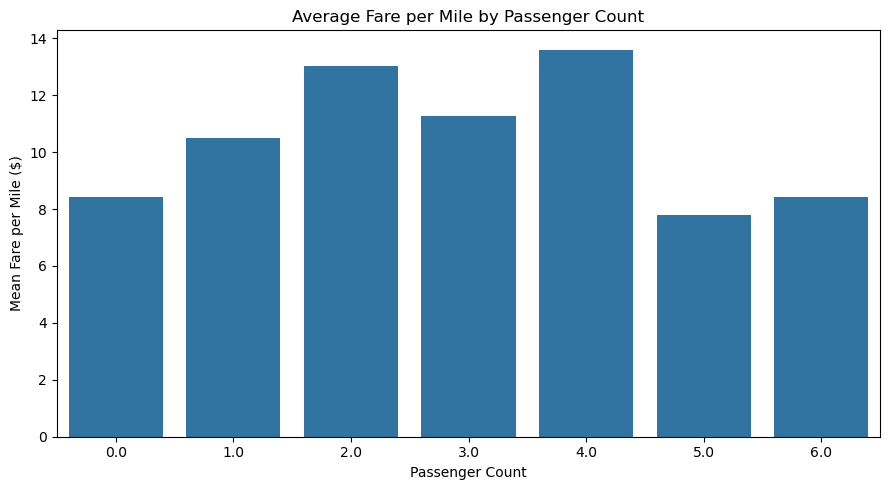

In [121]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fare_per_passenger,
    x="passenger_count",
    y="mean"
)

plt.title("Average Fare per Mile by Passenger Count")
plt.xlabel("Passenger Count")
plt.ylabel("Mean Fare per Mile ($)")
plt.tight_layout()
plt.show()

## Summary of General EDA Findings till now

The exploratory data analysis identified several patterns in NYC Yellow Taxi operations during 2023. These findings are based on the sampled trip records and should not be interpreted as complete citywide totals.

**Temporal patterns:** Pickup activity varied by hour and day of the week. The updated sample showed the highest pickup activity at 6 PM. Differences across weekdays and weekends indicate that taxi activity changes throughout the week.

**Financial patterns:** Total sampled revenue varied across months. May and October recorded relatively high revenue, while February was lower. Quarterly revenue contributions were relatively balanced, with the second and fourth quarters contributing the largest shares.

**Trip distance and fare:** Trip distance had a strong positive correlation with fare amount (approximately 0.945). Longer trips generally had higher fares, although unusual trip distances and fares were present. These observations warrant cautious interpretation rather than automatic removal.

**Trip duration:** After excluding records with invalid or implausible trip durations from the duration-specific analysis, fare amount showed a positive relationship with trip duration. This analysis used a separate filtered dataset and did not imply that the excluded records were invalid for every other analysis.

**Passenger count and tipping:** Median fare per mile was relatively similar across passenger-count categories, while mean fare per mile varied more noticeably. Tip amount also showed a positive relationship with trip distance, although the relationship was not perfect.

**Payment methods:** Credit card was the most common recorded payment type, followed by cash. A smaller number of records had other payment codes, including code 0, which was retained for further interpretation rather than automatically discarded.

**Geographic patterns:** Pickup and drop-off activity was concentrated in several Manhattan zones, while airport zones showed distinct pickup-to-drop-off patterns. Overnight activity was also concentrated in Manhattan, with East Village ranking highest for both pickups and drop-offs in the selected overnight period.

Overall, the analysis highlights temporal, financial, and geographic variation in sampled taxi activity. These findings can help guide further investigation into demand patterns, fare behavior, and operational planning. However, conclusions should account for the sampling approach, data-quality limitations, and the difference between observed sample totals and estimates of full-year activity.


#### Route-Speed Analysis


In [127]:
# Add drop-off zone information using unique location IDs
speed_df = df_merged_pickup.merge(
    zones_unique[["LocationID", "zone", "borough"]],
    left_on="DOLocationID",
    right_on="LocationID",
    how="left",
    validate="many_to_one"
)

# Rename columns for clarity
speed_df.rename(
    columns={
        "zone": "DO_zone",
        "borough": "DO_borough"
    },
    inplace=True
)

# Remove redundant join key
speed_df.drop(columns=["LocationID"], inplace=True)

print("Original trip records:", len(df_merged_pickup))
print("Rows after drop-off join:", len(speed_df))
print("Missing drop-off zone names:", speed_df["DO_zone"].isna().sum())

Original trip records: 260301
Rows after drop-off join: 260301
Missing drop-off zone names: 3344


In [128]:
# Create a separate DataFrame for route-speed analysis
speed_df = speed_df.copy()

# Calculate trip duration in minutes
speed_df["trip_duration_min"] = (
    speed_df["tpep_dropoff_datetime"]
    - speed_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Keep records suitable for speed analysis:
# positive distance, positive duration, and duration <= 180 minutes
speed_df = speed_df[
    (speed_df["trip_distance"] > 0) &
    (speed_df["trip_duration_min"] > 0) &
    (speed_df["trip_duration_min"] <= 180)
].copy()

# Calculate speed in miles per hour
speed_df["speed_mph"] = (
    speed_df["trip_distance"] / (speed_df["trip_duration_min"] / 60)
)

# Keep trips with both pickup and drop-off zone names
speed_df = speed_df.dropna(subset=["PU_zone", "DO_zone"])

print("Trips available for route-speed analysis:", len(speed_df))
print("Unique pickup-drop-off routes:", 
      speed_df[["PU_zone", "DO_zone"]].drop_duplicates().shape[0])
print("Average trip speed (mph):", round(speed_df["speed_mph"].mean(), 2))
print("Median trip speed (mph):", round(speed_df["speed_mph"].median(), 2))

Trips available for route-speed analysis: 256166
Unique pickup-drop-off routes: 9437
Average trip speed (mph): 12.13
Median trip speed (mph): 9.67


In [130]:
# Summarize speed by pickup and drop-off route
route_speed = (
    speed_df
    .groupby(["PU_zone", "DO_zone"])
    .agg(
        trip_count=("speed_mph", "size"),
        median_speed_mph=("speed_mph", "median"),
        average_speed_mph=("speed_mph", "mean")
    )
    .reset_index()
)

# Keep routes with sufficient observations
route_speed_filtered = route_speed[
    route_speed["trip_count"] >= 30
].copy()

# Fastest routes by median speed
fastest_routes = route_speed_filtered.sort_values(
    "median_speed_mph", ascending=False
).head(10)

fastest_routes

,PU_zone,DO_zone,trip_count,median_speed_mph,average_speed_mph
3915,JFK Airport,Windsor Terrace,30,35.655810,32.175494
3763,JFK Airport,Flushing Meadows-Corona Park,46,34.203563,33.436579
3688,JFK Airport,Bay Ridge,48,32.727898,33.966388
3746,JFK Airport,East Harlem South,64,31.220924,30.672856
3842,JFK Airport,Old Astoria,39,30.796957,30.418765
3818,JFK Airport,Marine Park/Mill Basin,42,30.543800,32.447699
3921,JFK Airport,Yorkville West,133,30.441297,30.335176
3725,JFK Airport,Cobble Hill,36,30.370708,29.019839
3902,JFK Airport,Washington Heights North,42,29.859217,30.451588
5751,Midtown East,Newark Airport,31,29.756458,28.507578


In [134]:
print(
    fastest_routes[
        [
            "PU_zone",
            "DO_zone",
            "trip_count",
            "median_speed_mph",
            "average_speed_mph"
        ]
    ].round(2).to_string(index=False, col_space=12)
)

     PU_zone                      DO_zone   trip_count  median_speed_mph  average_speed_mph
 JFK Airport              Windsor Terrace           30             35.66              32.18
 JFK Airport Flushing Meadows-Corona Park           46             34.20              33.44
 JFK Airport                    Bay Ridge           48             32.73              33.97
 JFK Airport            East Harlem South           64             31.22              30.67
 JFK Airport                  Old Astoria           39             30.80              30.42
 JFK Airport       Marine Park/Mill Basin           42             30.54              32.45
 JFK Airport               Yorkville West          133             30.44              30.34
 JFK Airport                  Cobble Hill           36             30.37              29.02
 JFK Airport     Washington Heights North           42             29.86              30.45
Midtown East               Newark Airport           31             29.76        

In [135]:
slowest_routes = route_speed_filtered.sort_values(
    "median_speed_mph",
    ascending=True
).head(10)

print(
    slowest_routes[
        [
            "PU_zone",
            "DO_zone",
            "trip_count",
            "median_speed_mph",
            "average_speed_mph"
        ]
    ].round(2).to_string(index=False)
)

                     PU_zone                      DO_zone  trip_count  median_speed_mph  average_speed_mph
            Garment District             Garment District          74              3.81              16.24
Penn Station/Madison Sq West             Garment District         152              4.45               5.37
              Midtown Center    Times Sq/Theatre District         397              4.50               4.87
   Times Sq/Theatre District    Times Sq/Theatre District         252              4.55               9.45
Penn Station/Madison Sq West Penn Station/Madison Sq West          85              4.81              22.76
                Midtown East    Times Sq/Theatre District         288              4.88               5.29
                Midtown East               Midtown Center         335              4.90               5.25
Penn Station/Madison Sq West                Midtown South         221              4.91               5.43
   West Chelsea/Hudson Yards         

### Route-Speed Analysis

Route-level speed analysis was performed using 256,166 trips with positive distances and valid durations not exceeding 180 minutes. Routes were grouped by pickup and drop-off zone, and only routes with at least 30 observations were retained.

The fastest routes were predominantly associated with JFK Airport. The fastest route by median speed was JFK Airport–Windsor Terrace, at approximately 35.66 mph across 30 trips.

In contrast, the slowest routes were concentrated in Midtown Manhattan, including the Garment District, Times Square, and Penn Station/Madison Square West. The Garment District–Garment District route had the lowest median speed, approximately 3.81 mph across 74 trips.

These results suggest that observed trip speeds vary considerably by route. Airport-related routes tend to have higher median speeds, whereas central Manhattan routes tend to have lower median speeds. Traffic congestion and short trip distances may contribute to this pattern, but further analysis would be needed to establish the causes.

The analysis uses a sampled dataset and excludes trips with nonpositive durations, nonpositive distances, or durations exceeding 180 minutes. The results should therefore be interpreted within those limitations.


#### Fare per Mile by Hour and Day


In [136]:
print("Available columns:")
print(df_cleaned_outliers.columns.tolist())

print("\nPickup datetime type:")
print(df_cleaned_outliers["tpep_pickup_datetime"].dtype)

Available columns:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'pickup_date', 'pickup_hour']

Pickup datetime type:
datetime64[us]


In [137]:
# Create a separate DataFrame for fare-per-mile analysis
fare_time_df = df_cleaned_outliers.copy()

# Keep valid trip distances
fare_time_df = fare_time_df[
    fare_time_df["trip_distance"] > 0
].copy()

# Calculate fare per mile
fare_time_df["fare_per_mile"] = (
    fare_time_df["fare_amount"] / fare_time_df["trip_distance"]
)

# Extract pickup day of week
fare_time_df["pickup_day"] = (
    fare_time_df["tpep_pickup_datetime"].dt.day_name()
)

# Extract pickup hour
fare_time_df["pickup_hour"] = (
    fare_time_df["tpep_pickup_datetime"].dt.hour
)

print("Trips available:", len(fare_time_df))
print("\nFare per mile summary:")
print(fare_time_df["fare_per_mile"].describe().round(2))

Trips available: 260301

Fare per mile summary:
count    260301.00
mean         10.86
std         122.99
min           0.00
25%           5.63
50%           7.14
75%           9.03
max       15090.00
Name: fare_per_mile, dtype: float64


In [138]:
# Inspect the highest fare-per-mile observations
print("Top 10 fare-per-mile observations:")

print(
    fare_time_df[
        [
            "trip_distance",
            "fare_amount",
            "fare_per_mile",
            "tpep_pickup_datetime"
        ]
    ]
    .sort_values("fare_per_mile", ascending=False)
    .head(10)
    .to_string(index=False)
)

# Count zero-fare and zero-fare-per-mile trips
print("\nTrips with zero fare:", (fare_time_df["fare_amount"] == 0).sum())

print(
    "Trips with zero fare per mile:",
    (fare_time_df["fare_per_mile"] == 0).sum()
)

Top 10 fare-per-mile observations:
 trip_distance  fare_amount  fare_per_mile tpep_pickup_datetime
          0.01        150.9        15090.0  2023-10-14 17:00:17
          0.01        110.0        11000.0  2023-12-04 04:55:04
          0.01        108.5        10850.0  2023-10-18 09:12:02
          0.01        100.0        10000.0  2023-12-01 15:07:20
          0.01         95.0         9500.0  2023-03-27 14:09:49
          0.01         90.0         9000.0  2023-12-08 20:27:22
          0.01         89.0         8900.0  2023-06-29 18:43:59
          0.01         86.5         8650.0  2023-06-22 16:47:49
          0.01         86.0         8600.0  2023-05-16 12:26:02
          0.01         85.0         8500.0  2023-04-10 17:11:56

Trips with zero fare: 0
Trips with zero fare per mile: 0


In [139]:
# Calculate the 99th-percentile threshold
fare_per_mile_99 = fare_time_df["fare_per_mile"].quantile(0.99)

print("99th-percentile fare-per-mile threshold:",
      round(fare_per_mile_99, 2))

# Create a separate dataset for this analysis
fare_time_filtered = fare_time_df[
    fare_time_df["fare_per_mile"] <= fare_per_mile_99
].copy()

print("Original trips:", len(fare_time_df))
print("Trips retained:", len(fare_time_filtered))
print("Trips excluded:", len(fare_time_df) - len(fare_time_filtered))
print("Mean fare per mile after filtering:",
      round(fare_time_filtered["fare_per_mile"].mean(), 2))
print("Median fare per mile after filtering:",
      round(fare_time_filtered["fare_per_mile"].median(), 2))

99th-percentile fare-per-mile threshold: 22.74
Original trips: 260301
Trips retained: 257698
Trips excluded: 2603
Mean fare per mile after filtering: 7.63
Median fare per mile after filtering: 7.12


In [140]:
# Set weekday order for correct presentation
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Median fare per mile by pickup hour
hourly_fare_per_mile = (
    fare_time_filtered
    .groupby("pickup_hour")
    .agg(
        median_fare_per_mile=("fare_per_mile", "median"),
        trip_count=("fare_per_mile", "size")
    )
    .reset_index()
    .sort_values("pickup_hour")
)

# Median fare per mile by day of the week
daily_fare_per_mile = (
    fare_time_filtered
    .groupby("pickup_day")
    .agg(
        median_fare_per_mile=("fare_per_mile", "median"),
        trip_count=("fare_per_mile", "size")
    )
    .reindex(weekday_order)
    .reset_index()
)

print("MEDIAN FARE PER MILE BY PICKUP HOUR")
print(hourly_fare_per_mile.round(2).to_string(index=False))

print("\nMEDIAN FARE PER MILE BY DAY OF THE WEEK")
print(daily_fare_per_mile.round(2).to_string(index=False))

MEDIAN FARE PER MILE BY PICKUP HOUR
 pickup_hour  median_fare_per_mile  trip_count
           0                  5.95        7256
           1                  5.86        4871
           2                  5.87        3181
           3                  5.63        2090
           4                  5.19        1370
           5                  5.16        1463
           6                  5.81        3544
           7                  6.46        7039
           8                  7.20        9762
           9                  7.35       11080
          10                  7.50       12036
          11                  7.73       12967
          12                  7.81       14098
          13                  7.70       14478
          14                  7.75       15576
          15                  7.77       15952
          16                  7.72       15904
          17                  7.69       17376
          18                  7.50       18244
          19            

### Median fare per mile by pickup hour

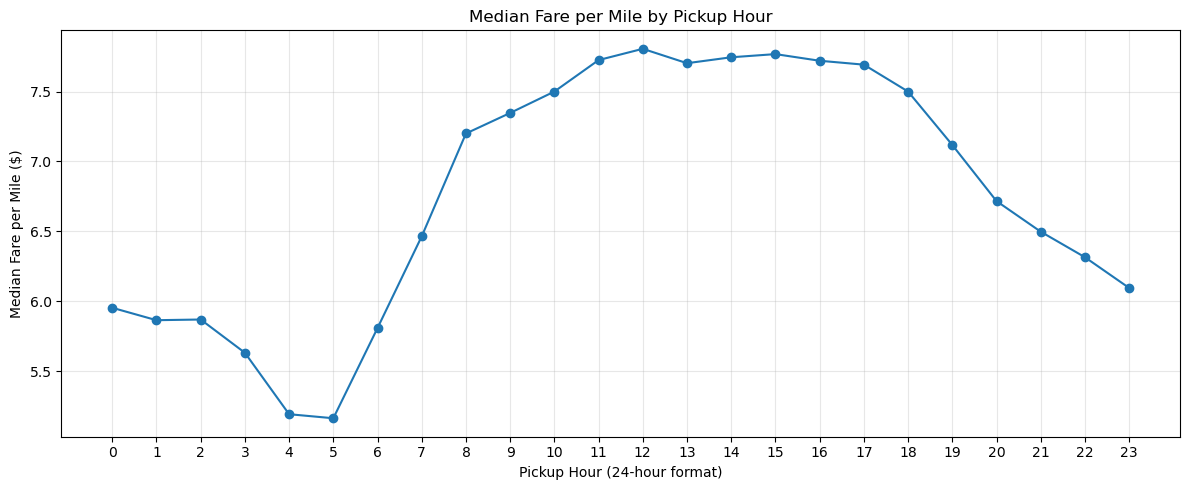

In [141]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_fare_per_mile["pickup_hour"],
    hourly_fare_per_mile["median_fare_per_mile"],
    marker="o"
)

plt.title("Median Fare per Mile by Pickup Hour")
plt.xlabel("Pickup Hour (24-hour format)")
plt.ylabel("Median Fare per Mile ($)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Median fare per mile by day of the week

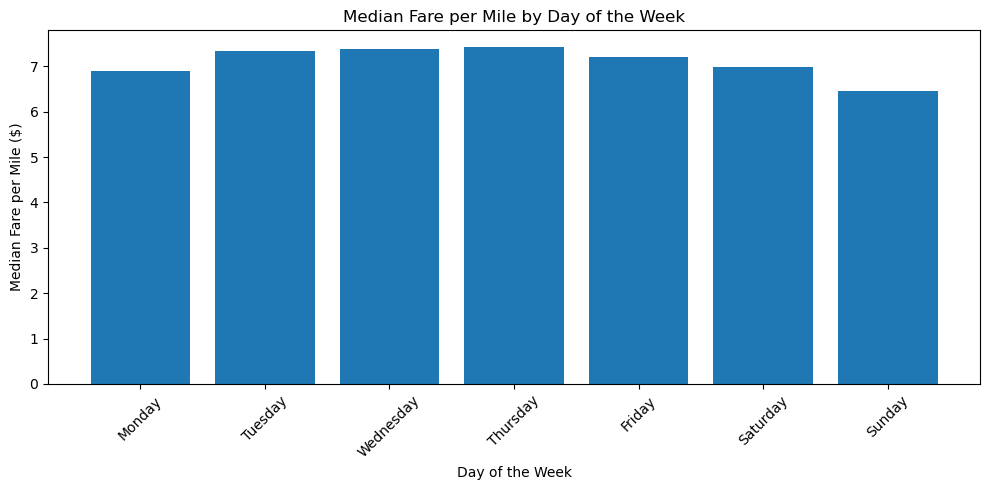

In [142]:
plt.figure(figsize=(10, 5))

plt.bar(
    daily_fare_per_mile["pickup_day"],
    daily_fare_per_mile["median_fare_per_mile"]
)

plt.title("Median Fare per Mile by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Median Fare per Mile ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Fare per Mile by Hour and Day

Median fare per mile was analysed by pickup hour and day of the week. To reduce the influence of extreme ratios, trips above the 99th percentile of fare per mile were excluded from this specific analysis. The resulting dataset contained 257,698 trips.

**Hourly patterns:** Median fare per mile was lowest during the early morning, reaching approximately 5.16 dollar at 4 AM. It increased through the morning and remained relatively stable during daytime hours, peaking at approximately 7.81 dollar around noon. Median fare per mile then declined during the evening, reaching approximately 6.10 dollar at 11 PM.

**Weekly patterns:** Thursday recorded the highest median fare per mile at approximately 7.42 dollar, while Sunday recorded the lowest at approximately 6.46 dollar. The remaining days had median values between these two figures.

Overall, the results show descriptive variation in median fare per mile across pickup hours and weekdays. These differences may reflect changes in trip characteristics, distance, and pricing conditions; the analysis does not establish causation. The findings also apply only to the sampled trips retained after the stated filtering.


#### Fare per Mile by Vendor and Hour


In [143]:
# Check trip counts by vendor
vendor_counts = (
    fare_time_filtered
    .groupby("VendorID")
    .size()
    .reset_index(name="trip_count")
    .sort_values("trip_count", ascending=False)
)

print(vendor_counts.to_string(index=False))

 VendorID  trip_count
        2      190928
        1       66702
        6          68


In [144]:
# Calculate median fare per mile and trip count by vendor and pickup hour
vendor_hourly_fare = (
    fare_time_filtered
    .groupby(["VendorID", "pickup_hour"])
    .agg(
        median_fare_per_mile=("fare_per_mile", "median"),
        trip_count=("fare_per_mile", "size")
    )
    .reset_index()
)

# Show results
print(vendor_hourly_fare.round(2).to_string(index=False))

 VendorID  pickup_hour  median_fare_per_mile  trip_count
        1            0                  5.94        1602
        1            1                  5.86        1115
        1            2                  5.82         711
        1            3                  5.70         460
        1            4                  5.15         335
        1            5                  5.32         418
        1            6                  5.92        1036
        1            7                  6.58        2000
        1            8                  7.18        2663
        1            9                  7.25        2993
        1           10                  7.60        3354
        1           11                  7.69        3576
        1           12                  7.80        3772
        1           13                  7.69        3932
        1           14                  7.76        4205
        1           15                  7.82        4318
        1           16         

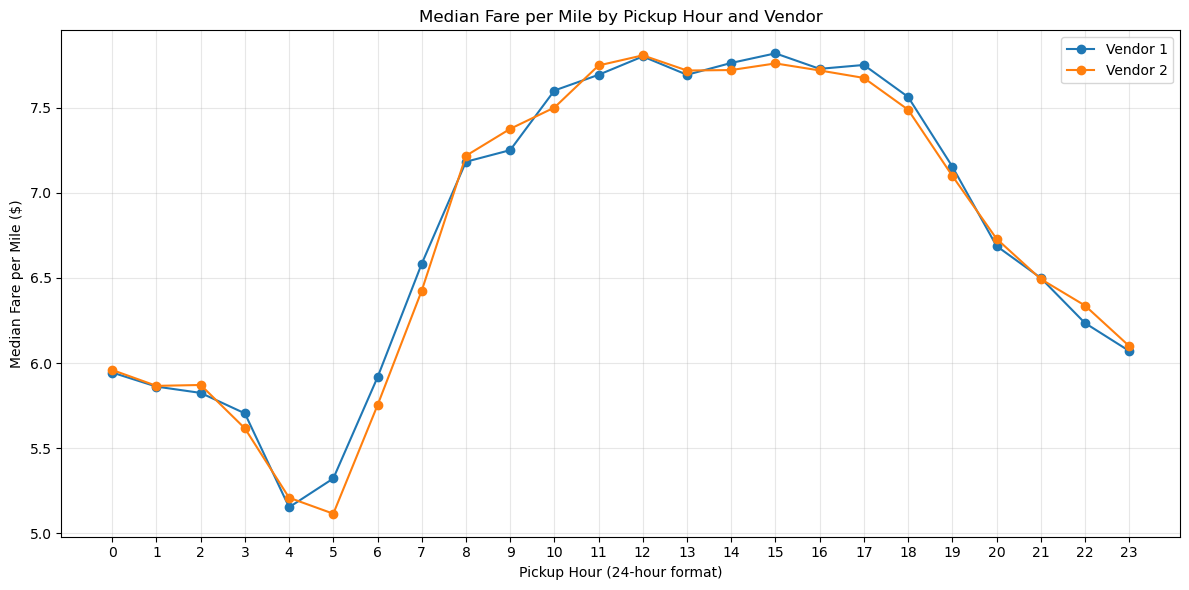

In [145]:
import matplotlib.pyplot as plt

# Keep the two vendors with sufficient observations
vendor_hourly_main = vendor_hourly_fare[
    vendor_hourly_fare["VendorID"].isin([1, 2])
].copy()

# Pivot for plotting
vendor_hourly_pivot = vendor_hourly_main.pivot(
    index="pickup_hour",
    columns="VendorID",
    values="median_fare_per_mile"
)

plt.figure(figsize=(12, 6))

plt.plot(
    vendor_hourly_pivot.index,
    vendor_hourly_pivot[1],
    marker="o",
    label="Vendor 1"
)

plt.plot(
    vendor_hourly_pivot.index,
    vendor_hourly_pivot[2],
    marker="o",
    label="Vendor 2"
)

plt.title("Median Fare per Mile by Pickup Hour and Vendor")
plt.xlabel("Pickup Hour (24-hour format)")
plt.ylabel("Median Fare per Mile ($)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Fare per Mile by Vendor and Hour

Median fare per mile was compared between Vendors 1 and 2 across pickup hours. Vendor 6 was excluded from the main comparison because it had only 68 trips in the filtered dataset, resulting in sparse hourly observations.

Both vendors displayed similar hourly patterns. Median fare per mile was lowest during the early morning, increased through the morning, remained relatively high during daytime hours, and declined during the evening.

The two vendors had comparable median fare-per-mile values throughout the day. Although small differences appeared at individual hours, neither vendor consistently recorded a higher median across all hours.

These findings suggest that the hourly pattern in median fare per mile was broadly similar for Vendors 1 and 2 in the sampled data. The analysis is descriptive and does not establish that vendor identity causes differences in fare per mile. The comparison also excludes the top 1% of fare-per-mile observations, as defined in the preceding analysis.


#### Fare per Mile by Distance Tier and Vendor


In [146]:
import pandas as pd

# Create a separate dataset for distance-tier analysis
distance_vendor_df = fare_time_filtered[
    fare_time_filtered["VendorID"].isin([1, 2])
].copy()

# Define trip-distance tiers
distance_bins = [0, 1, 2, 5, 10, float("inf")]

distance_labels = [
    "Very short (<=1 mile)",
    "Short (1-2 miles)",
    "Medium (2-5 miles)",
    "Long (5-10 miles)",
    "Very long (>10 miles)"
]

distance_vendor_df["distance_tier"] = pd.cut(
    distance_vendor_df["trip_distance"],
    bins=distance_bins,
    labels=distance_labels,
    include_lowest=True
)

# Check the number of trips in each tier by vendor
distance_counts = (
    distance_vendor_df
    .groupby(["distance_tier", "VendorID"], observed=True)
    .size()
    .reset_index(name="trip_count")
)

print(distance_counts.to_string(index=False))

        distance_tier  VendorID  trip_count
Very short (<=1 mile)         1       16652
Very short (<=1 mile)         2       38911
    Short (1-2 miles)         1       22040
    Short (1-2 miles)         2       63240
   Medium (2-5 miles)         1       17544
   Medium (2-5 miles)         2       53536
    Long (5-10 miles)         1        5351
    Long (5-10 miles)         2       17447
Very long (>10 miles)         1        5115
Very long (>10 miles)         2       17794


In [147]:
# Calculate median fare per mile by distance tier and vendor
distance_vendor_summary = (
    distance_vendor_df
    .groupby(["distance_tier", "VendorID"], observed=True)
    .agg(
        median_fare_per_mile=("fare_per_mile", "median"),
        mean_fare_per_mile=("fare_per_mile", "mean"),
        trip_count=("fare_per_mile", "size")
    )
    .reset_index()
)

print(
    distance_vendor_summary.round(2).to_string(index=False)
)

        distance_tier  VendorID  median_fare_per_mile  mean_fare_per_mile  trip_count
Very short (<=1 mile)         1                 10.20               10.88       16652
Very short (<=1 mile)         2                 10.12               10.86       38911
    Short (1-2 miles)         1                  7.60                8.00       22040
    Short (1-2 miles)         2                  7.72                8.21       63240
   Medium (2-5 miles)         1                  6.10                6.38       17544
   Medium (2-5 miles)         2                  6.25                6.53       53536
    Long (5-10 miles)         1                  4.59                4.77        5351
    Long (5-10 miles)         2                  4.66                4.86       17447
Very long (>10 miles)         1                  4.00                4.06        5115
Very long (>10 miles)         2                  4.02                4.13       17794


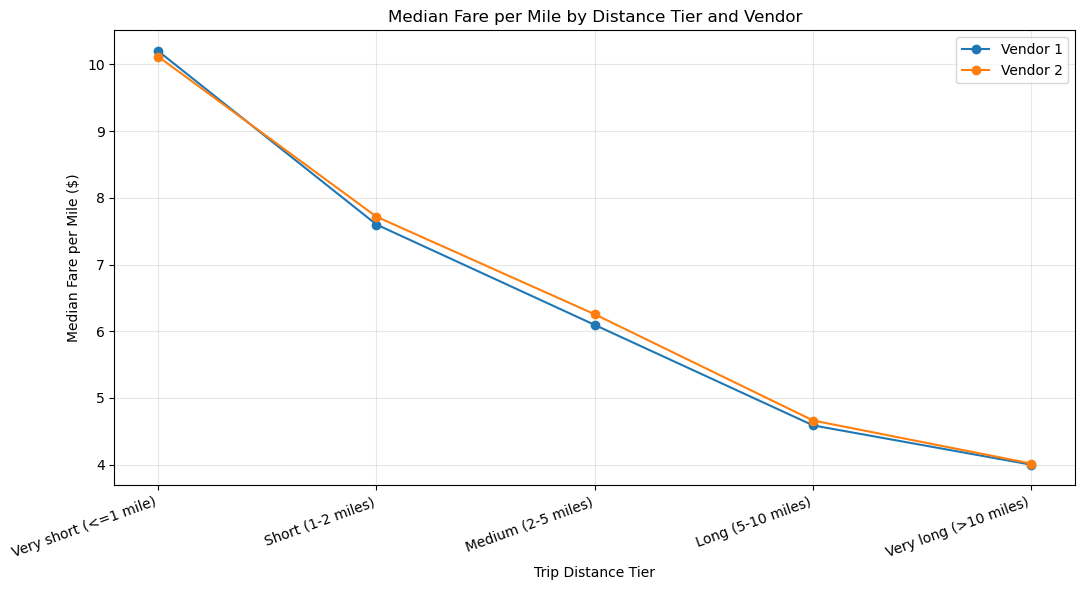

In [148]:
import matplotlib.pyplot as plt

distance_vendor_pivot = distance_vendor_summary.pivot(
    index="distance_tier",
    columns="VendorID",
    values="median_fare_per_mile"
)

# Preserve the intended distance order
distance_vendor_pivot = distance_vendor_pivot.reindex(distance_labels)

plt.figure(figsize=(11, 6))

plt.plot(
    distance_vendor_pivot.index,
    distance_vendor_pivot[1],
    marker="o",
    label="Vendor 1"
)

plt.plot(
    distance_vendor_pivot.index,
    distance_vendor_pivot[2],
    marker="o",
    label="Vendor 2"
)

plt.title("Median Fare per Mile by Distance Tier and Vendor")
plt.xlabel("Trip Distance Tier")
plt.ylabel("Median Fare per Mile ($)")
plt.xticks(rotation=20, ha="right")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Fare per Mile by Distance Tier and Vendor

Median fare per mile was compared across five trip-distance tiers for Vendors 1 and 2. Both vendors displayed a consistent decline in median fare per mile as trip distance increased.

Very short trips of up to one mile had the highest median fare per mile, at approximately 10.20 dollar for Vendor 1 and 10.12 dollar for Vendor 2. For medium trips of 2–5 miles, the medians decreased to 6.10 dollar and 6.25 dollar, respectively. Very long trips exceeding 10 miles had the lowest medians, at approximately 4.00 dollar per mile for both vendors.

The patterns for the two vendors were very similar across all distance categories, with only small differences in median fare per mile. Neither vendor consistently recorded a higher median across the tiers.

These results indicate that trip distance is associated with substantial differences in fare per mile in the sampled data. The analysis is descriptive and does not establish the causes of this relationship.


#### Tip Percentage Patterns


In [149]:
# Create a separate dataset for tip percentage analysis
tip_pct_df = fare_time_filtered[
    fare_time_filtered["fare_amount"] > 0
].copy()

# Calculate tip percentage relative to fare amount
tip_pct_df["tip_percentage"] = (
    tip_pct_df["tip_amount"] / tip_pct_df["fare_amount"]
) * 100

print("Trips available for tip percentage analysis:", len(tip_pct_df))

print("\nTip percentage summary:")
print(tip_pct_df["tip_percentage"].describe().round(2))

Trips available for tip percentage analysis: 257698

Tip percentage summary:
count    257698.00
mean         20.38
std          15.72
min           0.00
25%           8.85
50%          23.97
75%          29.07
max        2083.33
Name: tip_percentage, dtype: float64


In [150]:
# Inspect the 10 highest tip percentages
print(
    tip_pct_df[
        [
            "fare_amount",
            "tip_amount",
            "tip_percentage",
            "payment_type",
            "trip_distance"
        ]
    ]
    .sort_values("tip_percentage", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

# Count zero-tip trips
print(
    "\nZero-tip trips:",
    (tip_pct_df["tip_amount"] == 0).sum()
)

print(
    "Negative-tip trips:",
    (tip_pct_df["tip_amount"] < 0).sum()
)

 fare_amount  tip_amount  tip_percentage  payment_type  trip_distance
         7.2      150.00         2083.33             1           0.80
         8.6      101.17         1176.40             1           0.95
         9.3       99.99         1075.16             1           1.13
         7.2       74.50         1034.72             1           1.14
         5.8       48.00          827.59             1           0.33
         4.4       34.00          772.73             1           0.40
        22.6      168.15          744.03             1           5.70
         3.0       20.00          666.67             1          16.00
         3.7       20.00          540.54             1           0.18
         3.7       20.00          540.54             1           2.18

Zero-tip trips: 55447
Negative-tip trips: 0


In [151]:
# Calculate the 99th-percentile tip percentage threshold
tip_pct_99 = tip_pct_df["tip_percentage"].quantile(0.99)

print(
    "99th-percentile tip percentage threshold:",
    round(tip_pct_99, 2), "%"
)

# Create a separate filtered dataset
tip_pct_filtered = tip_pct_df[
    tip_pct_df["tip_percentage"] <= tip_pct_99
].copy()

print("\nOriginal trips:", len(tip_pct_df))
print("Trips retained:", len(tip_pct_filtered))
print("Trips excluded:", len(tip_pct_df) - len(tip_pct_filtered))

print(
    "\nMedian tip percentage after filtering:",
    round(tip_pct_filtered["tip_percentage"].median(), 2), "%"
)

print(
    "Mean tip percentage after filtering:",
    round(tip_pct_filtered["tip_percentage"].mean(), 2), "%"
)

99th-percentile tip percentage threshold: 50.47 %

Original trips: 257698
Trips retained: 255121
Trips excluded: 2577

Median tip percentage after filtering: 23.88 %
Mean tip percentage after filtering: 19.84 %


In [152]:
# Summarize tipping behaviour by payment type
tip_payment_summary = (
    tip_pct_filtered
    .groupby("payment_type")
    .agg(
        trip_count=("tip_percentage", "size"),
        median_tip_percentage=("tip_percentage", "median"),
        mean_tip_percentage=("tip_percentage", "mean"),
        zero_tip_count=("tip_amount", lambda x: (x == 0).sum())
    )
    .reset_index()
)

# Calculate percentage of trips with zero tips
tip_payment_summary["zero_tip_share_pct"] = (
    tip_payment_summary["zero_tip_count"]
    / tip_payment_summary["trip_count"]
    * 100
)

print(tip_payment_summary.round(2).to_string(index=False))

 payment_type  trip_count  median_tip_percentage  mean_tip_percentage  zero_tip_count  zero_tip_share_pct
            0        6986                  19.21                16.10            1619               23.17
            1      203329                  25.66                24.34            9031                4.44
            2       42469                   0.00                 0.00           42463               99.99
            3         825                   0.00                 0.06             823               99.76
            4        1512                   0.00                 0.02            1511               99.93


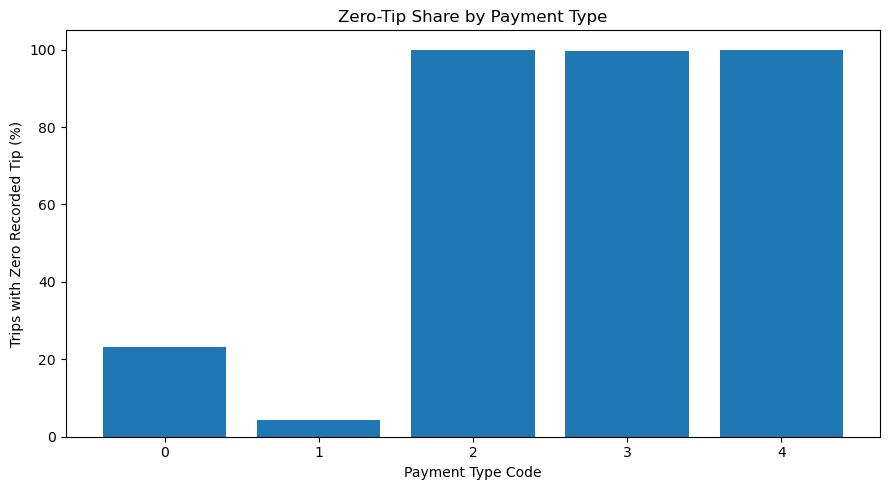

In [153]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    tip_payment_summary["payment_type"].astype(str),
    tip_payment_summary["zero_tip_share_pct"]
)

plt.title("Zero-Tip Share by Payment Type")
plt.xlabel("Payment Type Code")
plt.ylabel("Trips with Zero Recorded Tip (%)")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

### Tip Percentage Patterns by Payment Type

Tip percentages were calculated by dividing the recorded tip amount by the fare amount and multiplying by 100. To reduce the influence of extreme ratios, the top 1% of tip percentages were excluded from this specific analysis. Zero-tip trips were retained.

The results showed substantial differences in recorded tipping behaviour across payment type categories. Payment type 1 had a median tip percentage of 25.66%, with 4.44% of trips recording zero tips. Payment type 0 had a median tip percentage of 19.21%, with a zero-tip share of 23.17%.

Payment types 2, 3, and 4 had median tip percentages of zero, with approximately 99.76%–99.99% of trips recording no tip. Payment type 1 also accounted for the largest number of trips in the filtered dataset.

These findings indicate an association between payment type and recorded tipping behaviour in the sample. However, the payment type codes should be verified against the dataset documentation before assigning meanings to them. The analysis is descriptive and does not establish the causes of the observed differences.


#### Low-Tip vs High-Tip Comparison


In [154]:
# Calculate the median tip percentage
tip_median = tip_pct_filtered["tip_percentage"].median()

print("Median tip percentage:", round(tip_median, 2), "%")

# Create a separate DataFrame for comparison
tip_comparison_df = tip_pct_filtered.copy()

# Define groups
tip_comparison_df["tip_group"] = tip_comparison_df[
    "tip_percentage"
].apply(
    lambda x: "Low-tip" if x <= tip_median else "High-tip"
)

# Check group sizes
print("\nGroup sizes:")
print(tip_comparison_df["tip_group"].value_counts())

# Check median tip percentage in each group
print("\nMedian tip percentage by group:")
print(
    tip_comparison_df.groupby("tip_group")["tip_percentage"]
    .median()
    .round(2)
)

Median tip percentage: 23.88 %

Group sizes:
tip_group
Low-tip     127578
High-tip    127543
Name: count, dtype: int64

Median tip percentage by group:
tip_group
High-tip    28.77
Low-tip      8.70
Name: tip_percentage, dtype: float64


In [155]:
# Calculate trip duration in minutes
tip_comparison_df["trip_duration_min"] = (
    tip_comparison_df["tpep_dropoff_datetime"]
    - tip_comparison_df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

# Summarize trip characteristics by tip group
tip_group_summary = (
    tip_comparison_df
    .groupby("tip_group")
    .agg(
        trip_count=("tip_percentage", "size"),
        median_trip_distance=("trip_distance", "median"),
        median_fare_amount=("fare_amount", "median"),
        median_total_amount=("total_amount", "median"),
        median_duration_min=("trip_duration_min", "median"),
        median_tip_amount=("tip_amount", "median")
    )
    .reset_index()
)

print(tip_group_summary.round(2).to_string(index=False))

tip_group  trip_count  median_trip_distance  median_fare_amount  median_total_amount  median_duration_min  median_tip_amount
 High-tip      127543                  1.59                12.1                20.52                11.10               3.56
  Low-tip      127578                  2.30                16.3                22.40                15.47               1.00


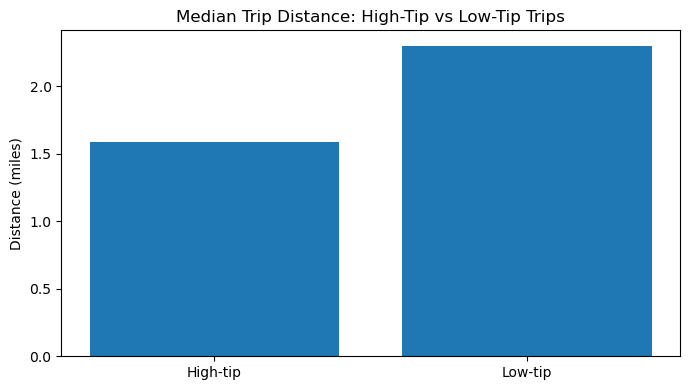

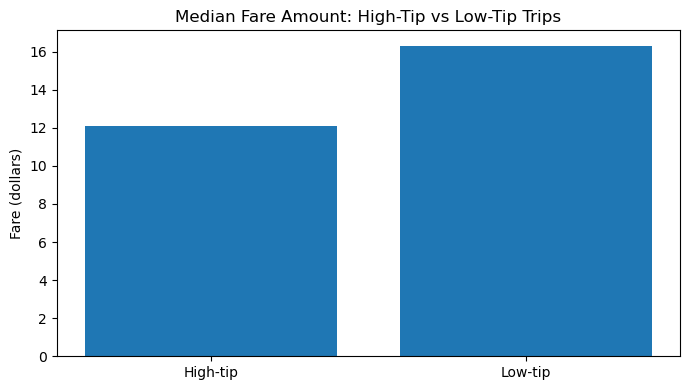

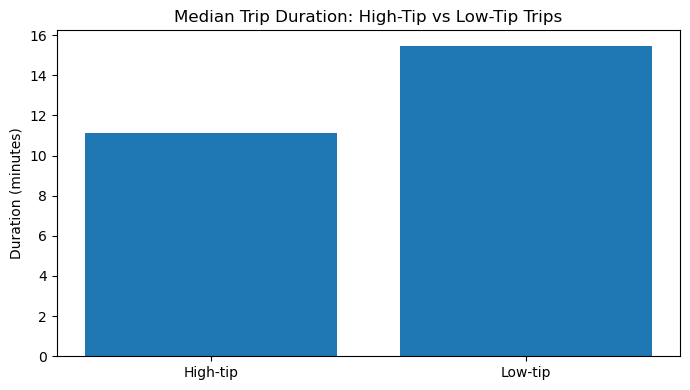

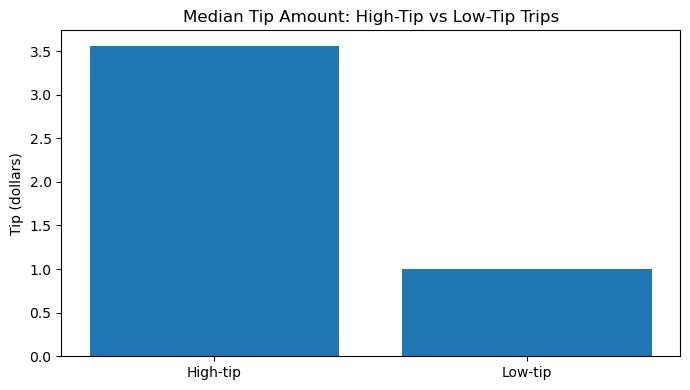

In [156]:
import matplotlib.pyplot as plt

metrics = [
    ("median_trip_distance", "Median Trip Distance", "Distance (miles)"),
    ("median_fare_amount", "Median Fare Amount", "Fare (dollars)"),
    ("median_duration_min", "Median Trip Duration", "Duration (minutes)"),
    ("median_tip_amount", "Median Tip Amount", "Tip (dollars)")
]

for column, title, ylabel in metrics:
    plt.figure(figsize=(7, 4))

    plt.bar(
        tip_group_summary["tip_group"],
        tip_group_summary[column]
    )

    plt.title(f"{title}: High-Tip vs Low-Tip Trips")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

### Findings: Low-Tip vs High-Tip Trips

The comparison reveals differences in trip characteristics between the low-tip and high-tip groups. High-tip trips had a median distance of 1.59 miles and a median fare of 12.10 dollars, compared with 2.30 miles and 16.30 dollars for low-tip trips.

High-tip trips also had a shorter median duration of 11.10 minutes, compared with 15.47 minutes for low-tip trips. Despite their shorter distances and lower fares, high-tip trips had a higher median tip amount of 3.56 dollars, compared with 1.00 dollar for low-tip trips.

These results suggest that higher tip percentages in this sample are associated with shorter trips, lower fares, and higher tip amounts. However, this is a descriptive comparison and does not establish a causal relationship. Because the groups were defined using tip percentage, the observed differences should be interpreted in that context. The analysis retained zero-tip trips and excluded the top 1% of tip percentages to reduce the influence of extreme values.


### Additional Charges by Zone and Time

In [157]:
# Examine additional-charge columns
additional_charge_cols = [
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "airport_fee"
]

df_merged_pickup[additional_charge_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
extra,260301.0,1.602096,1.838968,0.0,0.0,1.0,2.5,96.38
mta_tax,260301.0,0.496829,0.039743,0.0,0.5,0.5,0.5,0.80
tolls_amount,260301.0,0.597524,2.158015,0.0,0.0,0.0,0.0,41.30
improvement_surcharge,260301.0,0.999484,0.019321,0.0,1.0,1.0,1.0,1.00
congestion_surcharge,260301.0,2.328372,0.632152,0.0,2.5,2.5,2.5,2.50
airport_fee,253172.0,0.143463,0.465645,0.0,0.0,0.0,0.0,1.75


In [158]:
additional_charge_cols = [
    "extra",
    "mta_tax",
    "tolls_amount",
    "improvement_surcharge",
    "congestion_surcharge",
    "airport_fee"
]

# Calculate total additional charges per trip
df_merged_pickup["total_additional_charges"] = (
    df_merged_pickup[additional_charge_cols]
    .fillna(0)
    .sum(axis=1)
)

# Summarize additional charges by pickup zone
zone_additional_charges = (
    df_merged_pickup
    .groupby(["PU_borough", "PU_zone"], dropna=False)
    .agg(
        trip_count=("total_additional_charges", "size"),
        median_additional_charges=("total_additional_charges", "median"),
        mean_additional_charges=("total_additional_charges", "mean")
    )
    .reset_index()
)

# Focus on zones with at least 100 trips
zone_additional_charges = zone_additional_charges[
    zone_additional_charges["trip_count"] >= 100
]

zone_additional_charges.sort_values(
    "median_additional_charges",
    ascending=False
).head(15)

,PU_borough,PU_zone,trip_count,median_additional_charges,mean_additional_charges
199,Queens,LaGuardia Airport,8878,17.30,15.516816
177,Queens,East Elmhurst,1143,13.05,13.253272
193,Queens,JFK Airport,13444,9.80,9.278094
134,Manhattan,Meatpacking/West Village West,2282,5.00,5.693655
148,Manhattan,Times Sq/Theatre District,8678,5.00,6.309392
135,Manhattan,Midtown Center,12132,5.00,5.980111
136,Manhattan,Midtown East,9342,5.00,5.870815
137,Manhattan,Midtown North,7690,5.00,5.857073
138,Manhattan,Midtown South,6097,5.00,5.916124
140,Manhattan,Murray Hill,7667,5.00,5.803845


In [159]:
# Summarize additional charges by pickup hour
hourly_additional_charges = (
    df_merged_pickup
    .groupby("pickup_hour")
    .agg(
        trip_count=("total_additional_charges", "size"),
        median_additional_charges=("total_additional_charges", "median"),
        mean_additional_charges=("total_additional_charges", "mean")
    )
    .reset_index()
)

hourly_additional_charges

,pickup_hour,trip_count,median_additional_charges,mean_additional_charges
0,0,7306,5.0,6.058077
1,1,4906,5.0,5.830544
2,2,3213,5.0,5.676738
3,3,2115,5.0,5.823816
4,4,1398,5.0,6.540200
5,5,1482,5.0,7.069703
6,6,3565,4.0,5.711675
7,7,7073,4.0,5.459071
8,8,9825,4.0,5.409373
9,9,11165,4.0,5.464708


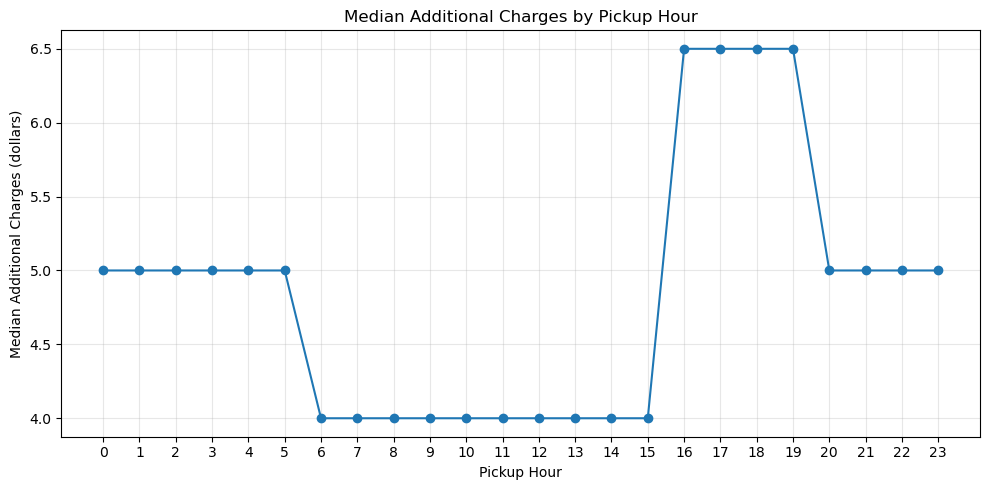

In [160]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_additional_charges["pickup_hour"],
    hourly_additional_charges["median_additional_charges"],
    marker="o"
)

plt.title("Median Additional Charges by Pickup Hour")
plt.xlabel("Pickup Hour")
plt.ylabel("Median Additional Charges (dollars)")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Findings: Additional Charges by Zone and Time

Geographic analysis revealed that airport pickup zones had higher median additional charges than most Manhattan zones. LaGuardia Airport had median additional charges of 17.30 dollars, followed by East Elmhurst at 13.05 dollars and JFK Airport at 9.80 dollars. In comparison, most of the examined Manhattan zones had median additional charges of 5.00 dollars.

The hourly analysis showed that median additional charges were 5.00 dollars from midnight through 5 AM, decreased to 4.00 dollars between 6 AM and 3 PM, and increased to 6.50 dollars between 4 PM and 7 PM. The median subsequently returned to 5.00 dollars from 8 PM through 11 PM.

These patterns suggest that additional charges vary across pickup locations and times of day. However, the analysis combines multiple charge categories, so the differences cannot be attributed to a single fee. Changes in the mix of pickup locations and trip characteristics may also contribute to the hourly pattern.

Missing airport-fee values were treated as zero when calculating total additional charges. This assumption is a limitation because a missing value does not necessarily mean that no fee was charged.


# Key Findings and Recommendations

## 1. Key Findings

### Demand and Temporal Patterns

* Pickup demand varies by hour and day of the week, indicating that taxi activity follows identifiable temporal patterns.
* Pickup activity changes throughout the day, supporting the use of hourly demand patterns to understand when taxi availability may be most important.
* Weekday and weekend activity differs, suggesting that fleet planning should consider day-specific demand rather than relying on a single schedule.

### Revenue and Fare Patterns

* Fare amounts, trip distances, and trip durations are related, although their relationship is not perfectly linear.
* Median fare per mile generally decreases as trip distance increases. In the analyzed sample, very short trips had a median fare per mile of approximately 10.12–10.20 dollars, while trips longer than 10 miles had a median of approximately 4.00 dollars for the two primary vendors.
* Median fare per mile varies by pickup hour and day of the week, with lower values during early morning hours and higher values around midday.
* The two primary vendors show broadly similar hourly and distance-based fare-per-mile patterns. The available data does not establish that one vendor consistently provides higher fare efficiency.

### Geographic Patterns

* Pickup and drop-off activity varies considerably across taxi zones.
* Airport pickup zones show substantially higher median additional charges than most of the examined Manhattan zones.
* Median additional charges at LaGuardia Airport were 17.30 dollars, compared with 9.80 dollars at JFK Airport and 5.00 dollars in many of the examined Manhattan zones.
* Route-speed analysis shows that median trip speeds vary by route. Airport-related routes appear among the faster routes, while routes within Midtown Manhattan appear among the slower ones. These differences are consistent with the influence of distance and traffic conditions, but the analysis does not isolate their individual effects.

### Passenger and Tipping Patterns

* Passenger counts vary across time periods and pickup zones.
* In the analyzed sample, trips in the high-tip-percentage group were generally shorter and had lower median fares than trips in the low-tip-percentage group.
* The high-tip group had a median tip amount of 3.56 dollars, compared with 1.00 dollar in the low-tip group.
* Tip percentages varied by payment type. The observed zero-tip patterns differed substantially across payment codes, although the codes should be interpreted using the dataset's documentation.

### Additional Charges

* Median additional charges varied by pickup hour: 4.00 dollars from 6 AM through 3 PM, 6.50 dollars from 4 PM through 7 PM, and 5.00 dollars during most other observed hours.
* These differences may reflect changes in the mix of pickup locations and charge types rather than a direct effect of pickup time.
* Missing airport-fee values were treated as zero for the combined-charge analysis. This assumption limits the interpretation of the resulting totals.

## 2. Operational and Fleet Positioning Recommendations

### Use Time-Based Demand Patterns

Use hourly and weekday pickup patterns to identify periods and locations that may benefit from additional taxi availability. Validate these patterns over multiple months and years before using them to set operational schedules.

### Prioritize High-Activity Zones

Use pickup and drop-off counts to identify consistently busy taxi zones. Consider these locations when planning driver positioning, while accounting for the possibility that high trip counts may reflect local geography or airport demand.

### Evaluate Airport and Manhattan Operations Separately

Airport zones and central Manhattan show different charge and route-speed patterns. Analyze them separately when assessing trip economics and operating conditions rather than applying a single operational strategy to every zone.

### Consider Route-Level Travel Conditions

Use route-level speed summaries to identify journeys that frequently experience low average speeds. Further analysis incorporating trip time, route distance, and traffic data would help distinguish congestion effects from differences in route length and location.

## 3. Pricing and Revenue Recommendations

### Evaluate Distance-Based Fare Patterns

The observed decline in median fare per mile with increasing trip distance suggests that fare efficiency differs across trip-length categories. Compare these patterns with the applicable fare structure before proposing pricing changes.

### Investigate Time-Based Fare Differences

Median fare per mile varies by pickup hour and day. Further analysis should determine whether these differences are associated with trip distance, congestion, additional charges, or other factors before considering pricing adjustments.

### Examine Additional Charges by Location

Airport pickup zones have higher median combined additional charges than many Manhattan zones. Break down the individual charge components and verify applicable fee rules before making recommendations about airport pricing or customer communication.

### Monitor Vendor-Level Patterns

The two primary vendors show similar fare-per-mile patterns across hours and distance tiers. Additional analysis controlling for trip characteristics would be needed before concluding that meaningful vendor-level differences exist.

## 4. Customer and Service Recommendations

### Investigate Tipping Patterns

The high-tip-percentage group had higher median tip amounts despite having shorter trips and lower median fares. Further analysis could examine whether this pattern remains after controlling for fare amount, trip duration, payment type, and pickup time.

### Understand Zero-Tip Trips

Zero-tip shares differ substantially across payment codes. Confirm the meaning of each code and investigate the associated trip characteristics before drawing conclusions about customer tipping behavior.

### Use Passenger Patterns for Service Planning

Passenger-count distributions across time and pickup zones can help describe how taxi services are used. Validate these patterns before making fleet-capacity or service-allocation decisions.

## 5. Limitations and Next Steps

* **Sample scope:** Findings are based on the analyzed sample of NYC Yellow Taxi trips from 2023 and may not represent every trip in the full-year dataset.
* **Outlier handling:** Certain records were excluded during cleaning, including extreme-distance records. Fare-per-mile and tip-percentage analyses also excluded the top 1% of their respective ratios to reduce the influence of extreme values.
* **Descriptive analysis:** Observed associations do not establish causation. Operational and pricing recommendations should be tested before implementation.
* **Additional-charge assumptions:** Missing airport-fee values were treated as zero when calculating combined charges; this may affect the results.
* **Route-speed limitations:** Average route speed was calculated from trip distance and elapsed time. It should not be interpreted as actual moving speed or as a direct measurement of congestion.
* **Further validation:** Future work could incorporate traffic conditions, official fare rules, additional months or years, and statistical testing to determine whether the observed patterns are robust.

## Conclusion

The analysis identifies meaningful variation in taxi demand, fare efficiency, route speed, tipping behavior, and additional charges across time and location. These findings provide a foundation for understanding taxi operations and identifying areas for further investigation. The strongest recommendations are to use demand patterns for operational planning, examine airport and Manhattan trips separately, and investigate pricing and tipping differences further before proposing policy changes.
